In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm

eps = 0.000001

save_tag = '15jul'

In [2]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

def mad(x):
    return np.median(np.abs(x - np.median(x)))

def rng(x):
    return x.max() - x.min()

def statistics(x):
    mean = np.mean(x)
    sd = np.std(x)
    median = np.median(x)
    q1 = np.percentile(x, 25)
    q3 = np.percentile(x, 75)
    iqr = q3 - q1
    return mean.item(), median.item(), sd.item(), iqr.item()


def remove_outlayer(x, method='3sigma', return_bin=True):
    mean, median, sd, iqr = statistics(x)
    if method == '3sigma':
        thr = 3               # 3 sigma
        z = (x - mean) / (sd + eps)
        binary = (z >= -thr) & (z <= thr)
        return binary if return_bin else x[binary]
    elif method == 'iqr':
        thr = 3
        q1, q3 = np.percentile(x, [25, 75])
        binary = (x >= (q1 - thr*iqr)) &  (x <= (q3 + thr*iqr))
        return binary if return_bin else x[binary]
    else:
        print('Method not implemented')
        return None


def remove_outlayer_df(df, assay, method):
    """
    method = ('3sigma', 'iqr')
    """
    
    binary = []
    for i in df['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assay]
        binary.extend(remove_outlayer(x, method).tolist())
    binary = np.array(binary)
    df_new = df.loc[binary].copy()
    return df_new
    

def normalize(x, control, method='mean', scale=False):
    mean, median, sd, iqr = statistics(control)
    if not scale:
        sd, iqr = 1, 1
    if method == 'mean':
        return (x - mean) / sd if sd > eps else 0
    elif method == 'median':
        return (x - median) / (iqr) if iqr > eps else 0
    else:
        print('Method not implemented')
        return None


def get_delta_values(df, df_ref, assay, method):
    df_ref[f'delta_{assay}'] = None
    for i in df_ref['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assay]
        control = df_ref.loc[df_ref['Plate_ID'] == i, assay]
        
        x = normalize(x, control, method=method, scale=False)
        df.loc[df['Plate_ID'] == i, f'delta_{assay}'] = x
        
        x = normalize(control, control, method=method, scale=False)
        df_ref.loc[df_ref['Plate_ID'] == i, f'delta_{assay}'] = x

    return df, df_ref
    

def emperical_p_value(x, null, alternative='two_sided', take_abs=False):
    if take_abs:
        null = np.abs(null)
        x = np.abs(x)
    if alternative == 'greater':
        p = np.mean(x <= null)
    elif alternative == 'less':
        p = np.mean(x >= null)
    elif  alternative == 'two_sided':
        p = np.mean(x <= null | x >= null)
    else:
        print('Invalid "alternative" parameter')
    return p


def boxplot_per_plate(df, assay, protein, title='', ordered=True, save_dir=None, ylim=None):
    # Plate-id orderes: 
    # to see original order use Plate_ID
    # to see them ordered based on numbers use Plate_ID_cat
    plate_id = 'Plate_ID_cat' if ordered else 'Plate_ID'
    
    plt.figure(figsize=(20, 6))

    df = df.loc[df['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df[plate_id].unique())
    plt.vlines(np.arange(0, n_plate, 2), ymin = -100, ymax = 100, colors='gray', linestyles='dashed', linewidth=0.5)
    sns.boxplot(data=df, x=plate_id, y=assay)
    
    plt.title(f'{assay} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assay.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()


def dotplot_per_plate(df, assay, protein, ids, title='', ordered=True, save_dir=None, ylim=None):
    
    plt.figure(figsize=(20, 6))
    df = df.loc[df['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df['Plate_ID_cat'].unique())
    
    df = df.loc[df['ID'].isin(ids)]
    
    plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
    plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)
    
    sns.stripplot(data=df, x='Plate_ID_cat', y=assay, hue='ID', dodge=True, jitter=True, size=4)
    
    plt.title(f'{assay} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assay.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()


def pos_ctrl_qc(df, protein, pos_ctrl, assay, return_thr=True):
    df_tmp = df.loc[(df['Protein'] == protein) & (df['ID'] == pos_ctrl)].copy()
    x = remove_outlayer(np.array(df_tmp[assay]), method='iqr', return_bin=False)
    df_tmp[f'abnormal_{pos_ctrl}_{protein}_{assay}'] = 0
    x_max, x_min = x.max(), x.min()
    df_tmp.loc[df_tmp[assay] > x_max, f'abnormal_{pos_ctrl}_{assay}'] = 1
    df_tmp.loc[df_tmp[assay] < x_min, f'abnormal_{pos_ctrl}_{assay}'] = 1
    df_qc_updated = df_tmp.groupby('Plate_ID')[f'abnormal_{pos_ctrl}_{assay}'].sum()
    return df_qc_updated, [x_min, x_max] if return_thr else df_qc_updated

In [4]:
# Read data
df_main = pd.read_excel("data/CS11207682_ini2810_20250515.xlsx")
#df_main = df_main.drop('Unnamed: 0', axis=1)
df_main.shape, len(df_main['Plate_ID'].unique())

((42688, 21), 116)

In [5]:
# Find the control compounds
# Their 'Formula' should be 'NaN'
ctlr_compounds = df_main.loc[df_main['Formula'].isna(), 'ID'].unique()
ctlr_compounds

array(['DMSO', 'FAD', 'minoA71', 'convUCR389'], dtype=object)

In [6]:
# Find the proteins
df_main['Protein'].unique()

array(['GCDH-V400M', 'GCDH-WT', 'failed'], dtype=object)

In [8]:
df_main[(df_main['Protein'] == 'GCDH-WT') & (~df_main['ID'].isin(ctlr_compounds))].shape

(18240, 21)

In [12]:
# Remove all lines where there is no result for TSA and SpSh and the failed ones

df = df_main.dropna(subset = 'Thermal_Shift').copy()
df = df.dropna(subset = 'Spectral_Shift').copy()
df = df.loc[df['Protein'] != 'failed'].copy()
df['Protein'].unique()

array(['GCDH-WT'], dtype=object)

In [13]:
df[(df['Protein'] == 'GCDH-WT') & (~df['ID'].isin(ctlr_compounds))].shape

(16000, 21)

In [14]:
# Make categorical plate ids with sorted levels based on numbers
df_plate_ids = pd.DataFrame({'ids' : df['Plate_ID'].unique()})
df_plate_ids['ids_no_letter'] = [i[1:] if i[0].isalpha() else i for i in df_plate_ids['ids']]
df_plate_ids = df_plate_ids.sort_values('ids_no_letter')
df_plate = df_plate_ids['ids']
df['Plate_ID_cat'] = pd.Categorical(df['Plate_ID'], categories=df_plate, ordered=True)

In [15]:
# define df control (DMSO) and other
ctrl_id = 'DMSO'
df_ctrl = df.loc[df['ID'] == ctrl_id].copy()   # always: negtive control (DMSO)
df_other = df.loc[df['ID'] != ctrl_id].copy()

In [23]:
'../data/analysis_data/TSA_analysis/G-1014/fig_final/GCDH_A02_dosage.jpeg'

/Users/Conny/Documents/My_Codes/screen_analysis/notebooks


In [26]:
l = df_ctrl.loc[df_ctrl['Plate_ID']=='G-1014', 'Well'].tolist()
l

['B01',
 'B02',
 'D01',
 'D02',
 'F01',
 'F02',
 'H01',
 'H02',
 'J01',
 'J02',
 'L01',
 'L02',
 'M02',
 'N01',
 'N02',
 'O02',
 'P01',
 'P02']

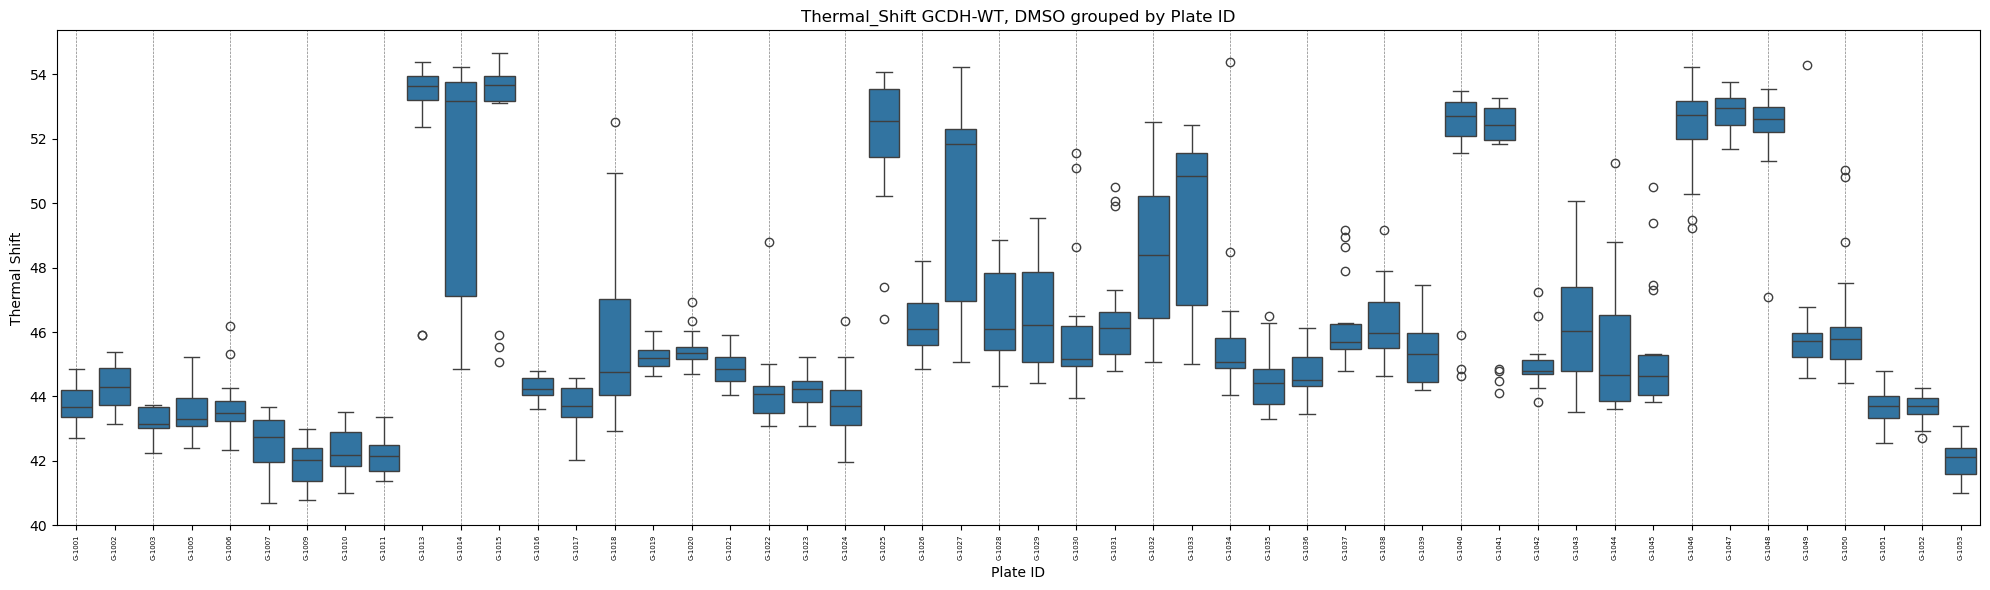

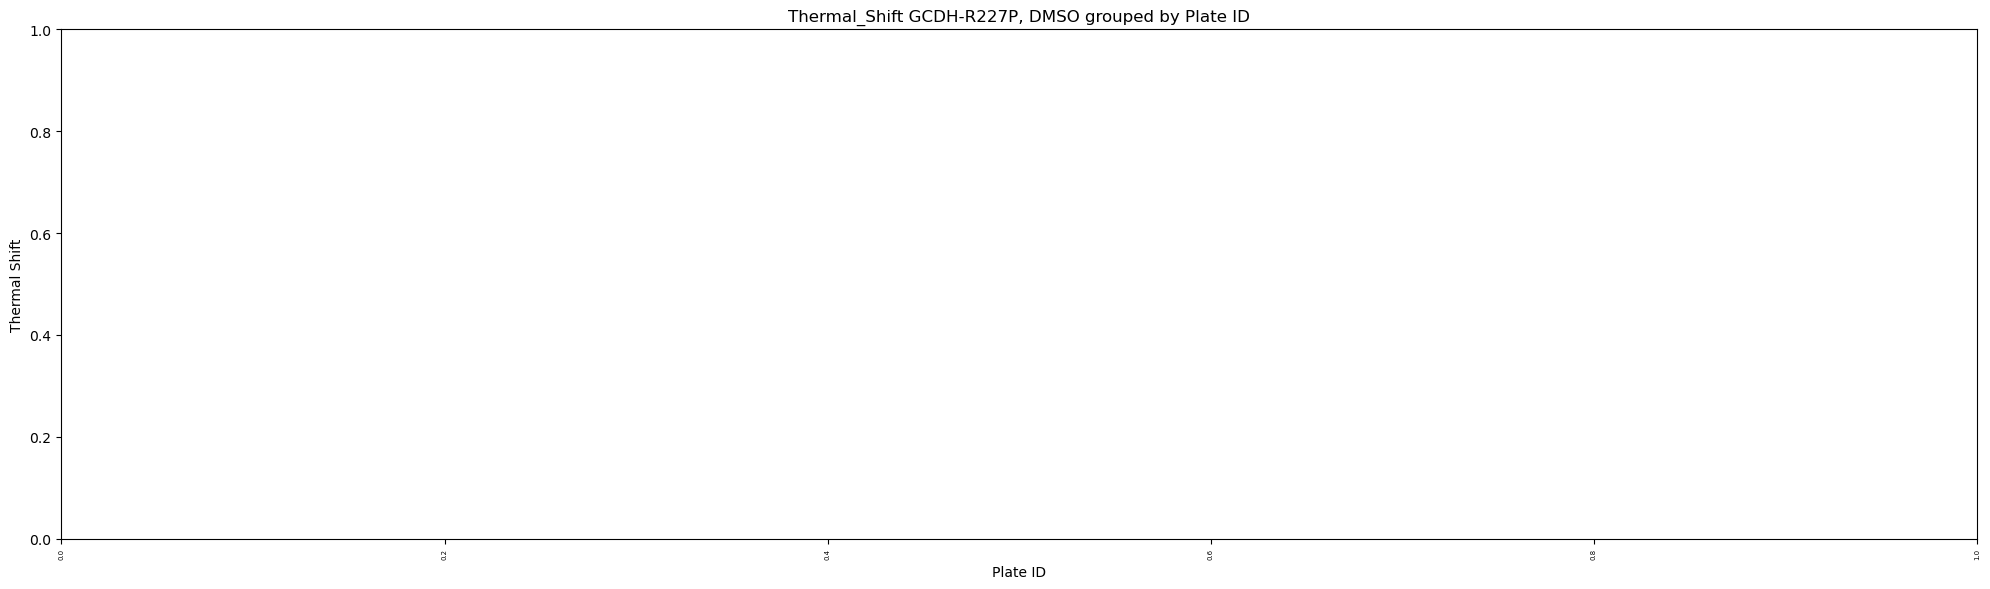

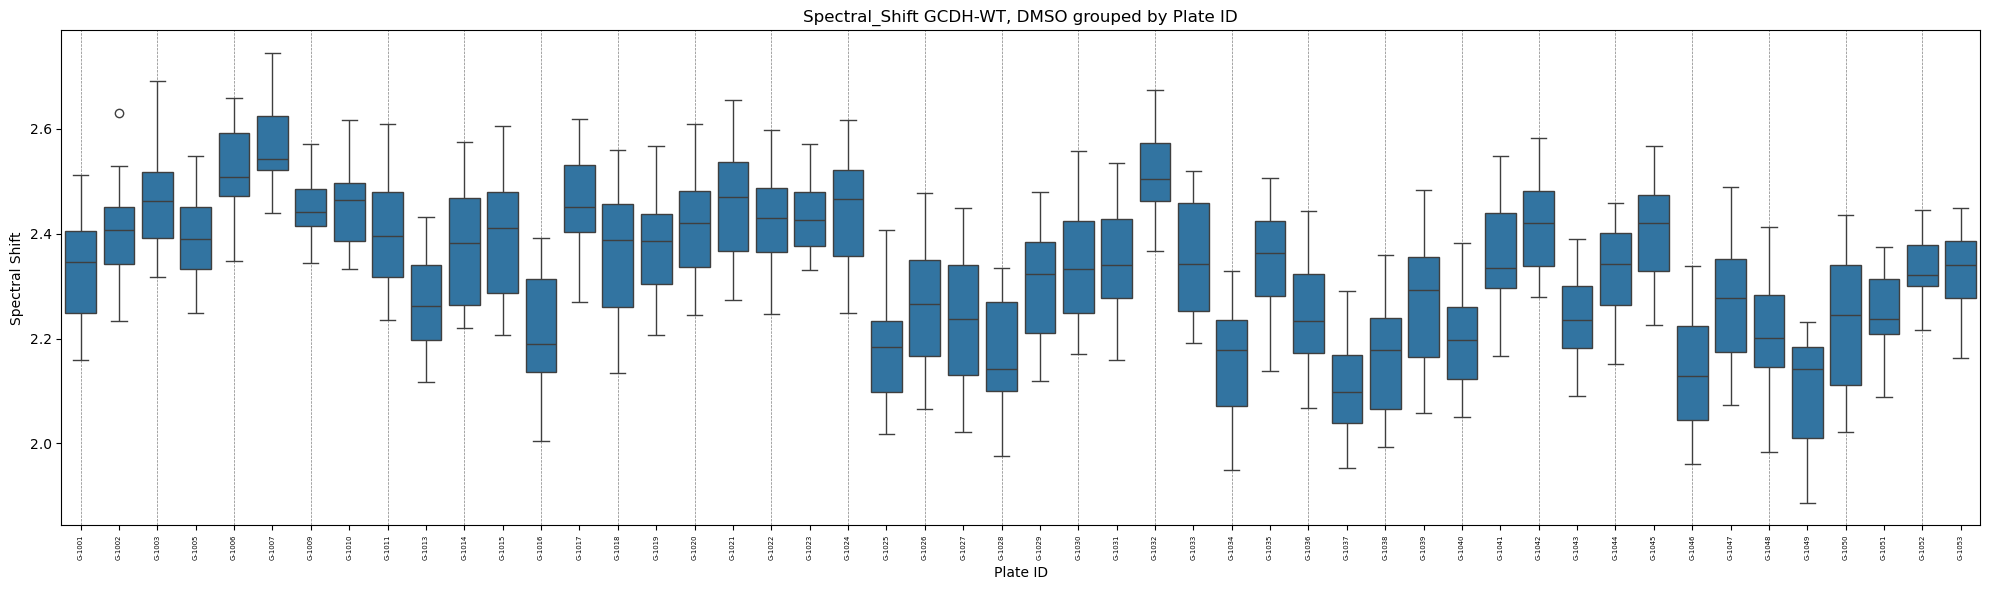

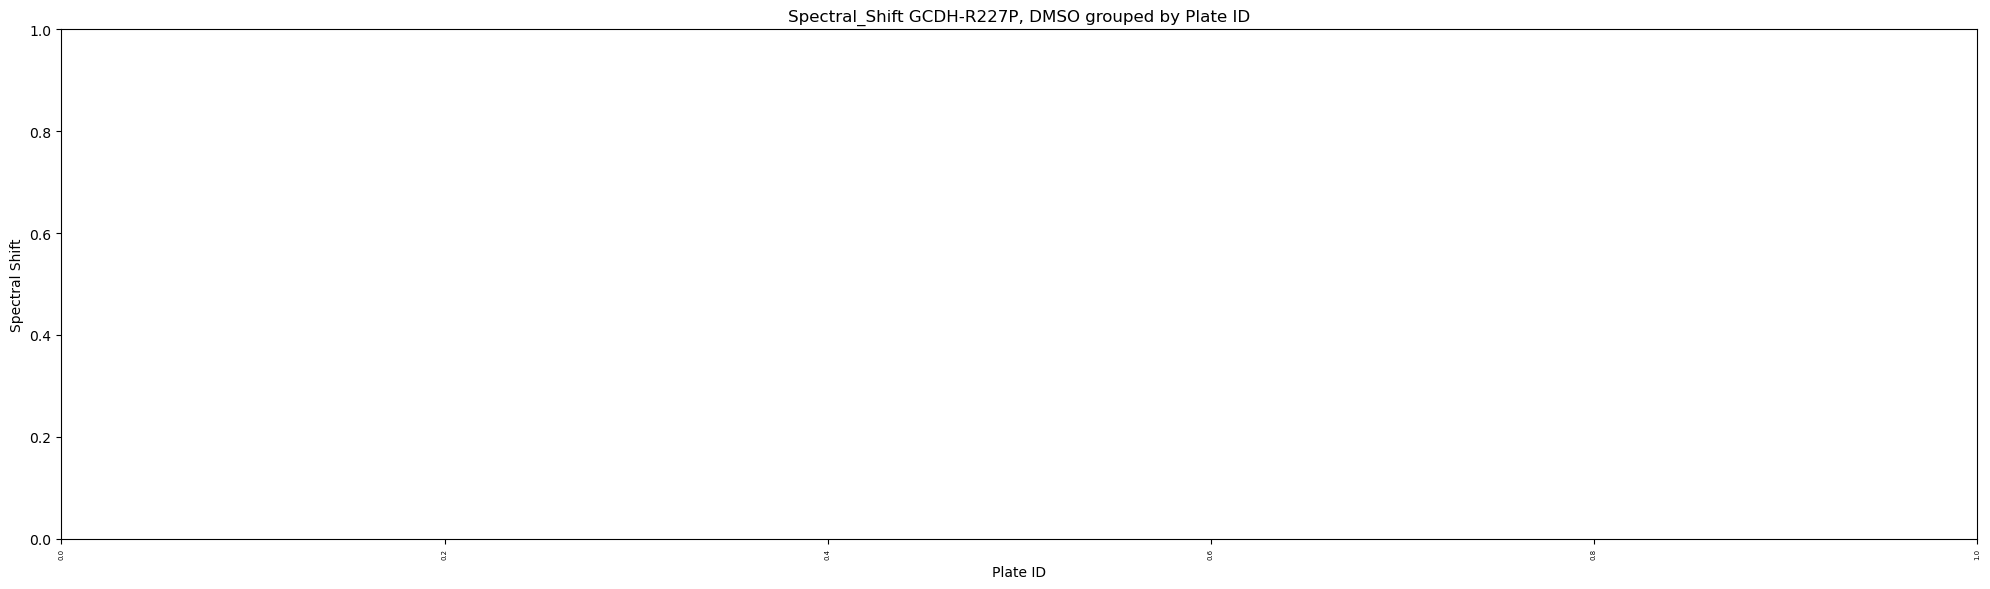

In [17]:
# Plot before outlier removal

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'GCDH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'GCDH-R227P', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'GCDH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'GCDH-R227P', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

In [27]:
# Get QC initial table
df_qc = (
    df_ctrl
    .groupby('Plate_ID_cat', observed=True)
    .agg({
        'Protein': 'first',
        'Thermal_Shift': ['median', iqr],
        'Spectral_Shift': ['median', iqr],
        'Fluorescence_at_25' : ['median', iqr]
    })
)
df_qc.columns = ['Protein', 'TSA_median', 'TSA_iqr', 'SpSh_median', 'SpSh_iqr', 'fl25_median', 'fl25_iqr']
df_qc.head()

,Protein,TSA_median,TSA_iqr,SpSh_median,SpSh_iqr,fl25_median,fl25_iqr
Plate_ID_cat,,,,,,,
G-1001,GCDH-WT,43.66895,0.817900,2.345187,0.156046,73001.595756,9217.402746
G-1002,GCDH-WT,44.30090,1.152475,2.406480,0.108203,63439.273976,6274.689426
G-1003,GCDH-WT,43.14850,0.650525,2.463239,0.126644,74095.135765,7599.852357
G-1005,GCDH-WT,43.29720,0.873625,2.390071,0.117781,71762.992512,5230.774386
G-1006,GCDH-WT,43.48305,0.650600,2.507368,0.120605,64796.608374,5836.043221


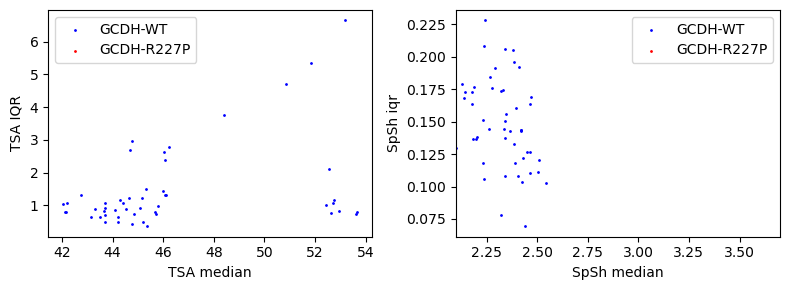

In [28]:
# Look at each plate

fig, ax = plt.subplots(1, 2, figsize=(8, 3))

# First subplot (TSA)
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'GCDH-WT', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'GCDH-WT', 'TSA_iqr'],
              s=1, color='blue', label='GCDH-WT')
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'GCDH-R227P', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'GCDH-R227P', 'TSA_iqr'],
              s=1, color='red', label='GCDH-R227P')
ax[0].set_xlabel('TSA median')
ax[0].set_ylabel('TSA IQR')
ax[0].legend()

# Second subplot (SpSh)
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'GCDH-WT', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'GCDH-WT', 'SpSh_iqr'],
              s=1, color='blue', label='GCDH-WT')
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'GCDH-R227P', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'GCDH-R227P', 'SpSh_iqr'],
              s=1, color='red', label='GCDH-R227P')
ax[1].set_xlabel('SpSh median')
ax[1].set_ylabel('SpSh iqr')
ax[1].legend()
ax[1].set_xlim([2.1, 3.7])
plt.tight_layout()
plt.show()


/Users/Conny/miniconda3/envs/screen/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/Conny/miniconda3/envs/screen/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/Conny/miniconda3/envs/screen/lib/python3.11/site-packages/numpy/_core/_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/Conny/miniconda3/envs/screen/lib/python3.11/site-packages/numpy/_core/_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/Users/Conny/miniconda3/envs/screen/lib/python3.11/site-packages/numpy/_core/_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


IndexError: index -1 is out of bounds for axis 0 with size 0

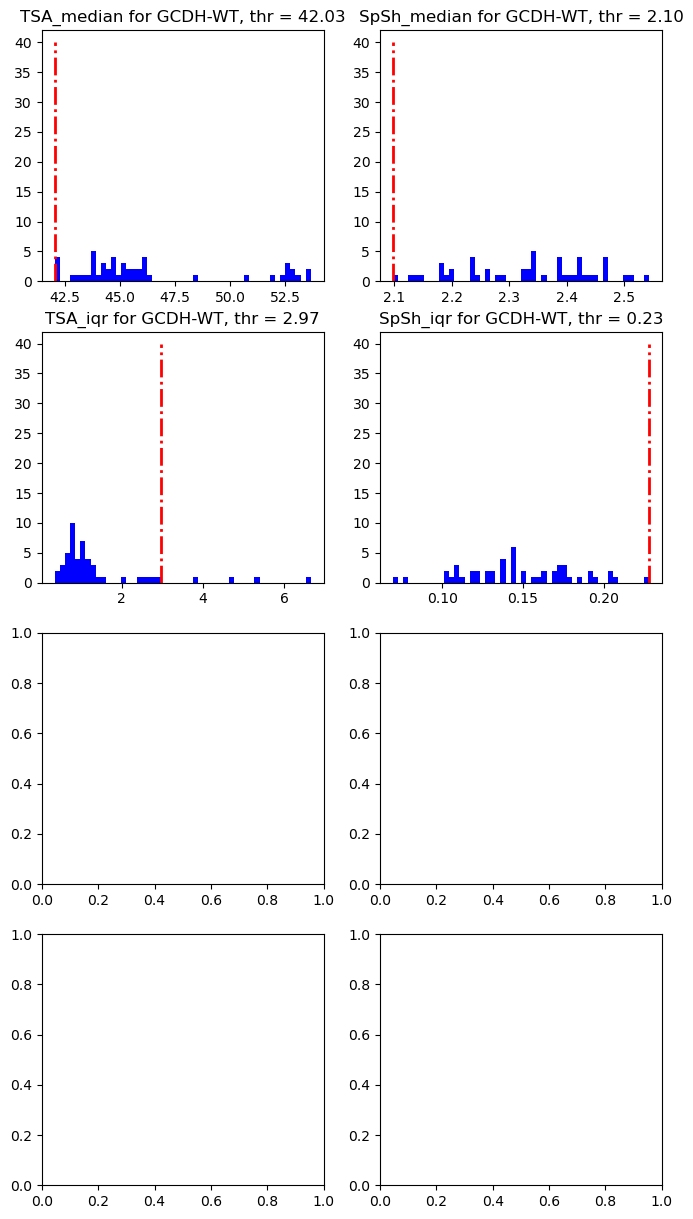

In [29]:
# Remove plates based on mean and IQR method
plot_outlier = []

fig, ax = plt.subplots(4, 2, figsize=(8, 15))
ax = ax.flatten()
th_set = {}

i = 0
for prot in ['GCDH-WT', 'GCDH-R227P']:
    for col in ['TSA_median', 'SpSh_median', 'TSA_iqr', 'SpSh_iqr']:
        df_tmp = df_qc.loc[df_qc['Protein'] == prot].copy()
        x = remove_outlayer(np.array(df_tmp[col]), method='iqr', return_bin=False)

        if col.split('_')[1] in ['median', 'mean']:
            thr = x.min()
            plot_outlier.extend(list(df_tmp.loc[df_tmp[col] < thr].index))
        else:
            thr = x.max()
            plot_outlier.extend(list(df_tmp.loc[df_tmp[col] > thr].index))
            # thr = x.min()
            # plot_outlier.extend(list(df_tmp.loc[df_tmp[col] < thr].index))

        th_set[f'{col}_{prot}'] = thr
        ax[i].hist(df_tmp[col], 50, color='blue');
        ax[i].vlines(thr, ymin=0, ymax=40, colors='red', linestyles='-.', linewidth=2)
        ax[i].set_title(f'{col} for {prot}, thr = {thr:.2f}');
        i += 1

KeyError: 'TSA_median_GCDH-R227P'

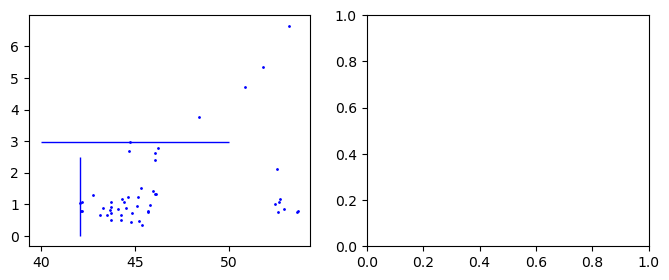

In [33]:
# Look at each plate

fig, ax = plt.subplots(1, 2, figsize=(8, 3))

# First subplot (TSA)
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'GCDH-WT', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'GCDH-WT', 'TSA_iqr'],
              s=1, color='blue', label='GCDH-WT')
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'GCDH-R227P', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'GCDH-R227P', 'TSA_iqr'],
              s=1, color='red', label='GCDH-R227P')

ax[0].vlines(th_set[f'TSA_median_GCDH-WT'], ymin=0, ymax=2.5, colors='blue', linewidth=1)
ax[0].hlines(th_set[f'TSA_iqr_GCDH-WT'], xmin=40, xmax=50, colors='blue', linewidth=1)
ax[0].vlines(th_set[f'TSA_median_GCDH-R227P'], ymin=0, ymax=2.5, colors='red', linewidth=1)
ax[0].hlines(th_set[f'TSA_iqr_GCDH-R227P'], xmin=40, xmax=50, colors='red', linewidth=1)

ax[0].set_xlabel('TSA median')
ax[0].set_ylabel('TSA IQR')
ax[0].legend()

# Second subplot (SpSh)
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'GCDH-WT', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'GCDH-WT', 'SpSh_iqr'],
              s=1, color='blue', label='GCDH-WT')
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'GCDH-R227P', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'GCDH-R227P', 'SpSh_iqr'],
              s=1, color='red', label='GCDH-R227P')

ax[1].vlines(th_set[f'SpSh_median_GCDH-WT'], ymin=0, ymax=.4, colors='blue', linewidth=1)
ax[1].hlines(th_set[f'SpSh_iqr_GCDH-WT'], xmin=2, xmax=3.5, colors='blue', linewidth=1)
ax[1].vlines(th_set[f'SpSh_median_GCDH-R227P'], ymin=0, ymax=.4, colors='red', linewidth=1)
ax[1].hlines(th_set[f'SpSh_iqr_GCDH-R227P'], xmin=2, xmax=3.5, colors='red', linewidth=1)

ax[1].set_xlabel('SpSh median')
ax[1].set_ylabel('SpSh iqr')
ax[1].legend()
ax[1].set_xlim([2.1, 3.7])

plt.tight_layout()
plt.show()


In [ ]:
df_qc['out_of_distribution'] = 'no'
df_qc.loc[df_qc.index.isin(plot_outlier), 'out_of_distribution'] = 'yes'
df_qc

In [ ]:
len(set(plot_outlier))

In [ ]:
# Remove outlier plates from the original df
df_outlier_removed = df.loc[~df['Plate_ID'].isin(plot_outlier)].copy()
df_outlier_removed.shape

In [ ]:
# Get df_ctrl and df_other again
ctrl_id = 'DMSO'
df_ctrl = df_outlier_removed.loc[df_outlier_removed['ID'] == ctrl_id].copy()
df_other = df_outlier_removed.loc[df_outlier_removed['ID'] != ctrl_id].copy()

In [ ]:
# Remove DMSO outlayer

print(df_ctrl.shape)

df_ctrl = remove_outlayer_df(df_ctrl, 
                             assay = 'Thermal_Shift', 
                             method = 'iqr'
                            )
df_ctrl = remove_outlayer_df(df_ctrl, 
                             assay = 'Spectral_Shift', 
                             method = 'iqr'
                            )
print(df_ctrl.shape)

# Which one? 
# remove outlier plates, and then remove dmso smaples or the other way around?
# The first scenario is more strict. So, let's move with it.

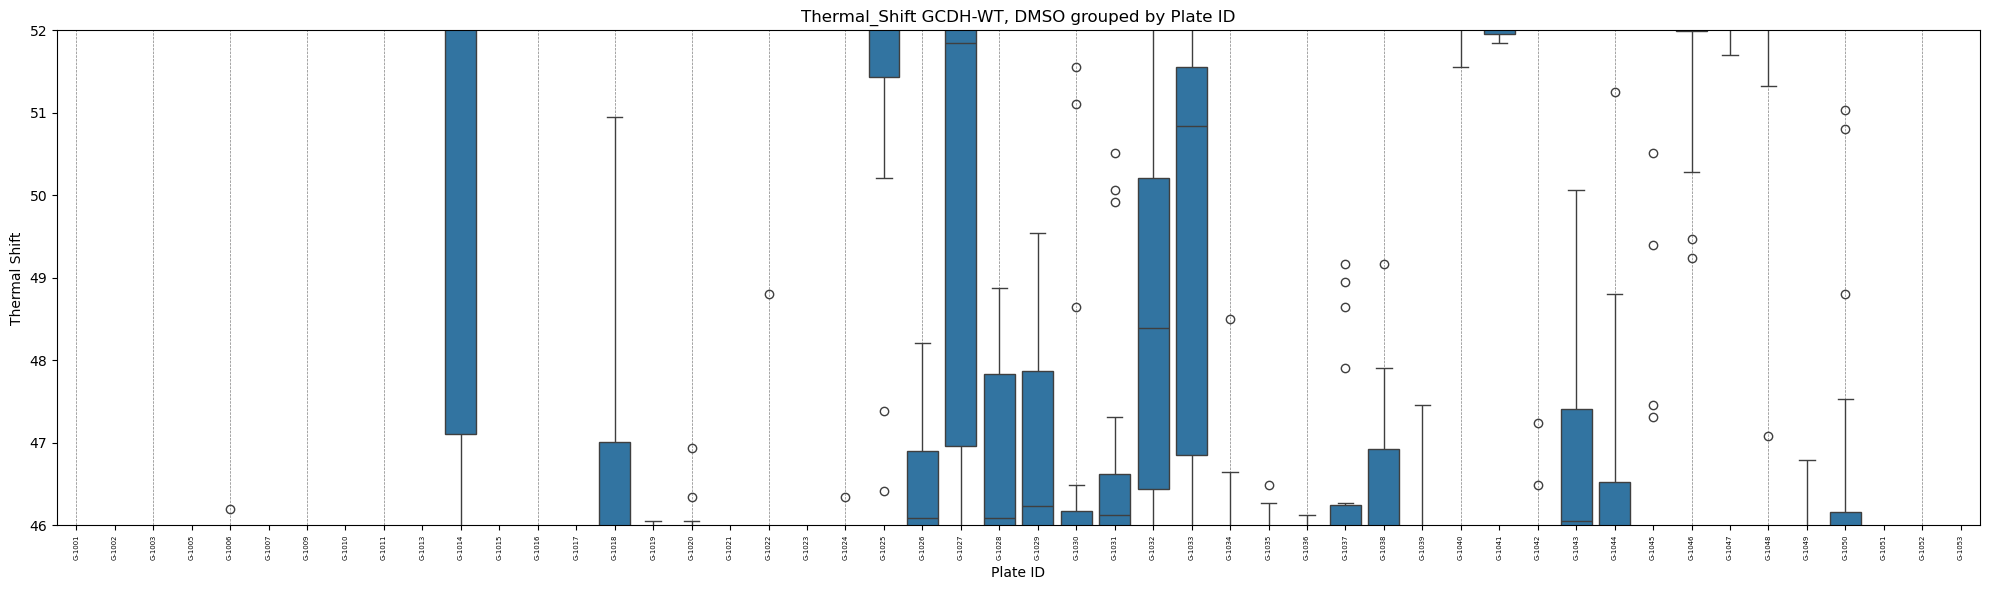

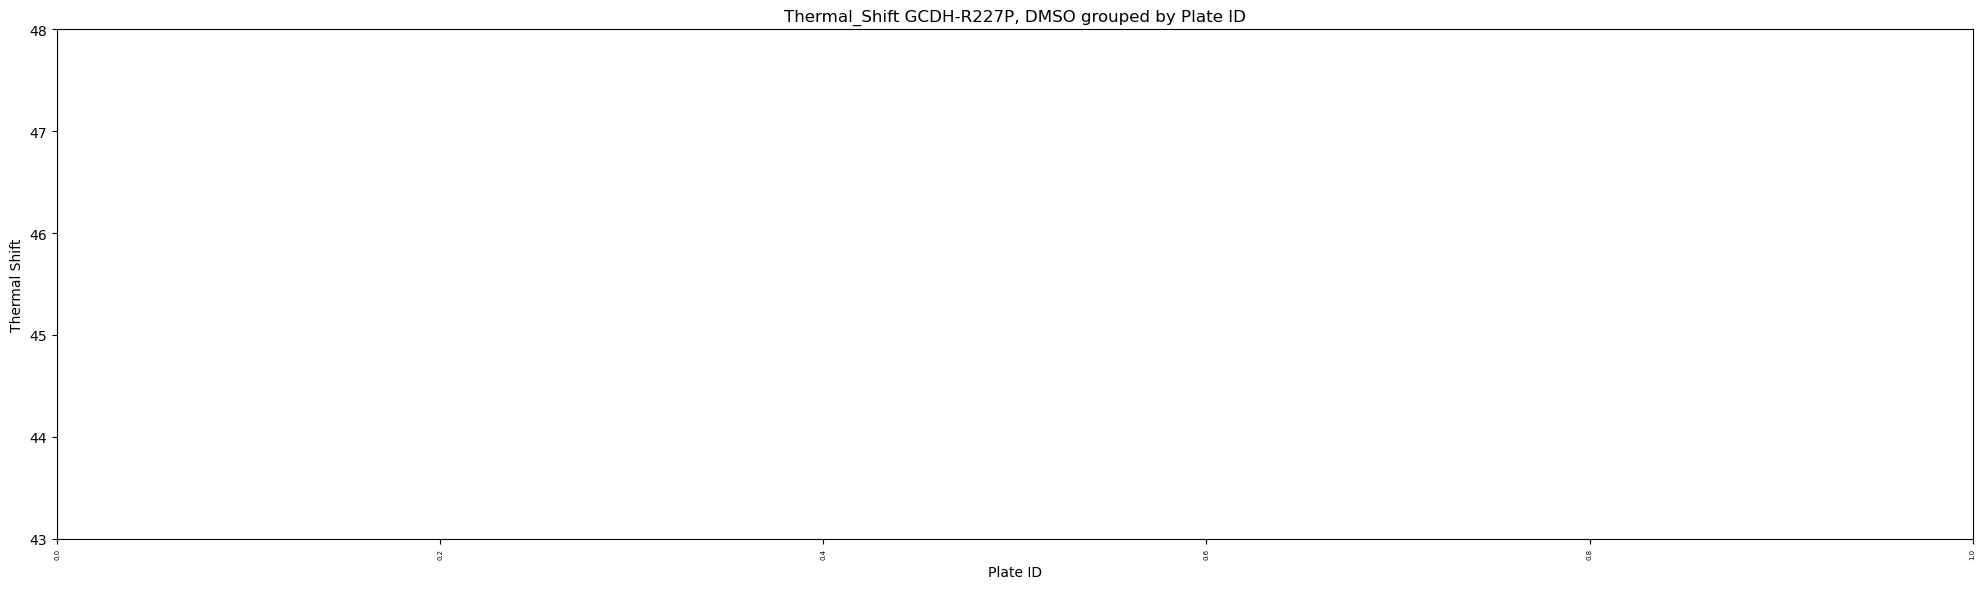

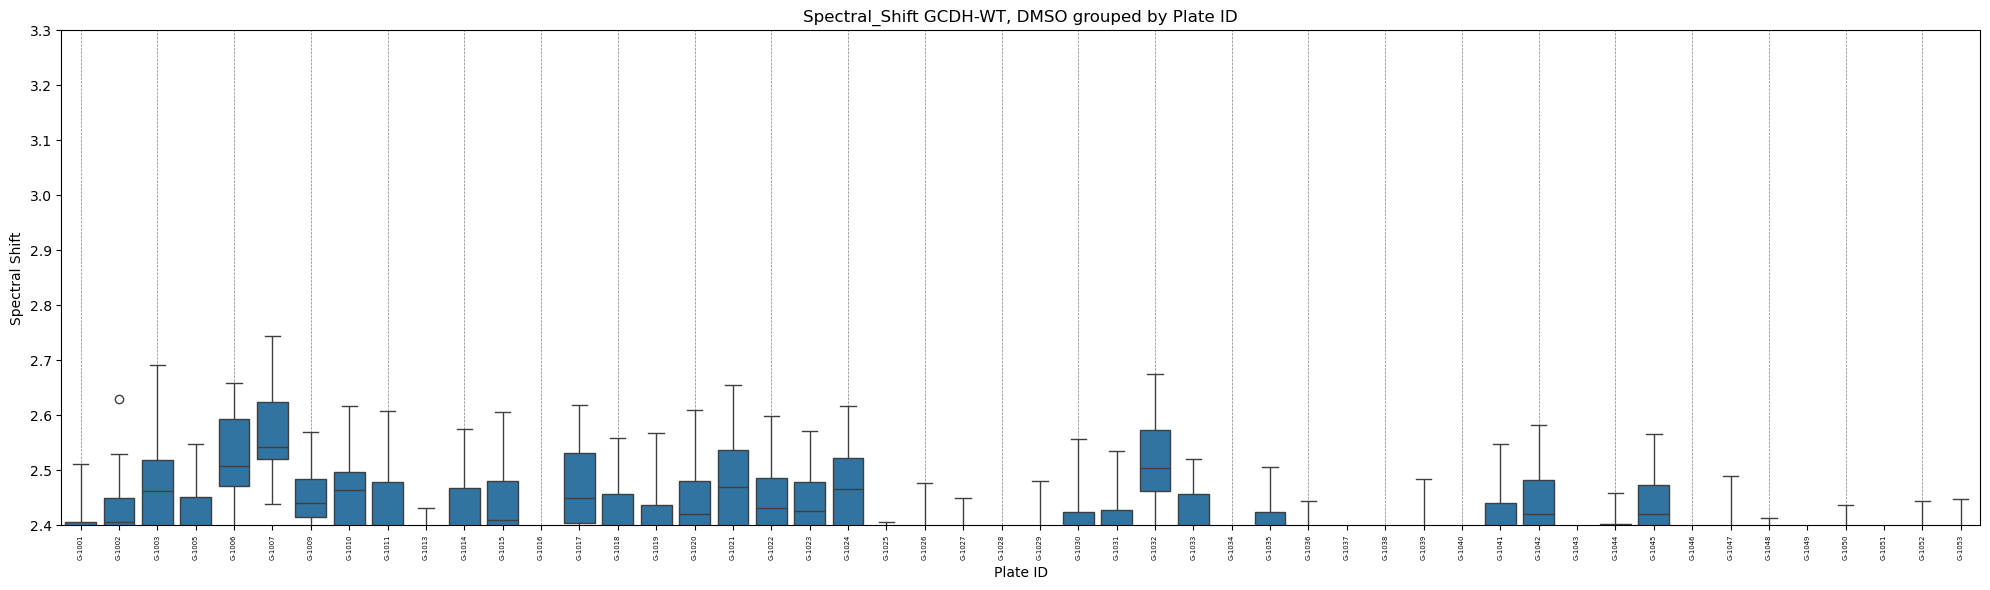

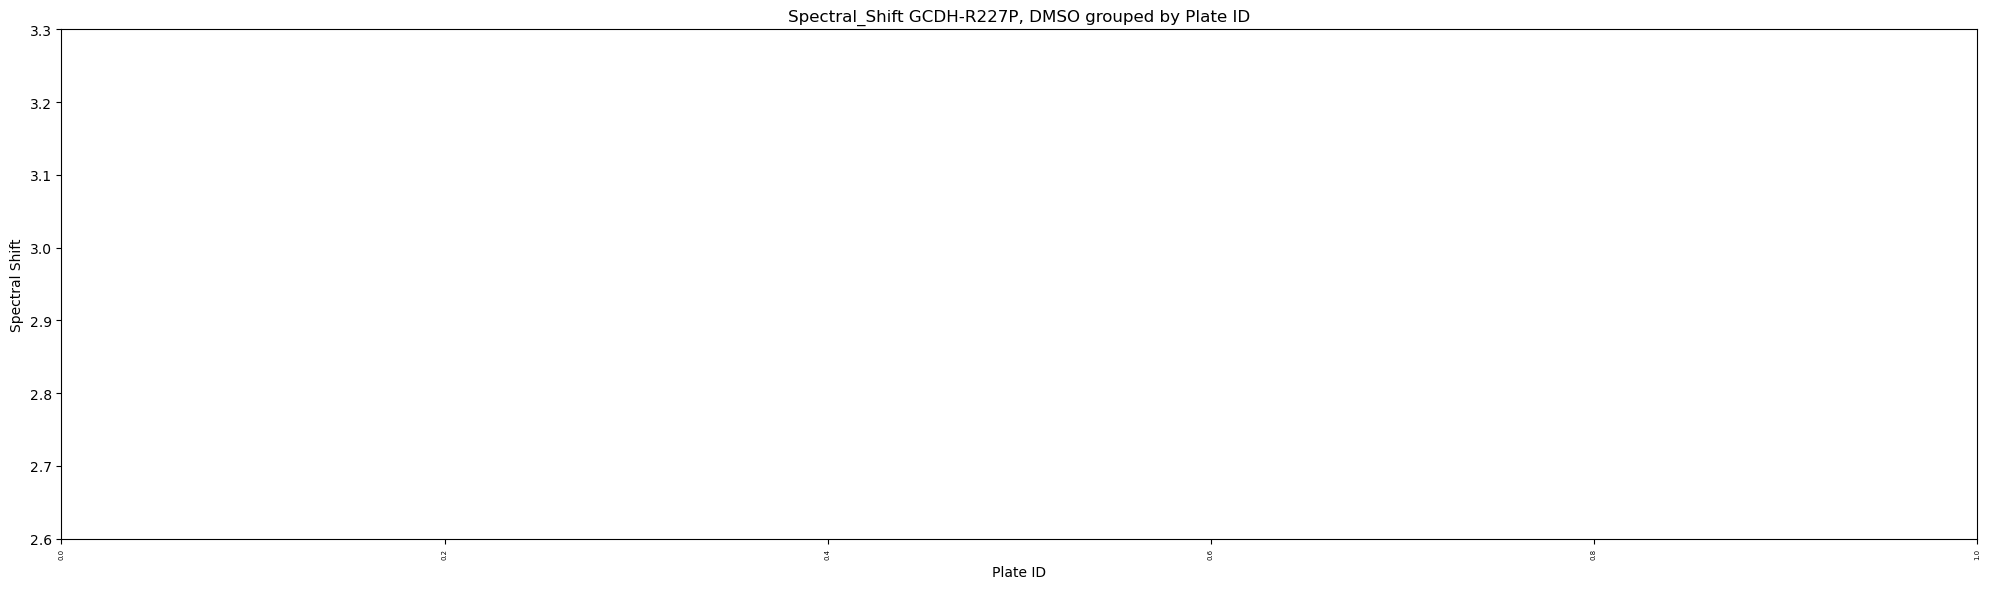

In [30]:
# Plot after outlier removal

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'GCDH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[46, 52]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'GCDH-R227P', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[43, 48]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'GCDH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[2.4, 3.3]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'GCDH-R227P', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[2.6, 3.3]
                 )

In [31]:
iqr_other = df_other.groupby('Plate_ID')['Thermal_Shift'].agg(iqr)
iqr_crtl = df_ctrl.groupby('Plate_ID')['Thermal_Shift'].agg(iqr)
iqr_other = np.array(iqr_other)
iqr_crtl = np.array(iqr_crtl)

np.corrcoef(iqr_other, iqr_crtl)[0, 1], np.std(iqr_other)

(np.float64(0.36118724102749555), np.float64(2.3785238989394237))

In [32]:
iqr_other = df_other.groupby('Plate_ID')['Spectral_Shift'].agg(iqr)
iqr_crtl = df_ctrl.groupby('Plate_ID')['Spectral_Shift'].agg(iqr)
iqr_other = np.array(iqr_other)
iqr_crtl = np.array(iqr_crtl)

np.corrcoef(iqr_other, iqr_crtl)[0, 1], np.std(iqr_other)

(np.float64(0.612109926674501), np.float64(0.028232874751767206))

In [36]:
# Delta values generation (subtract DMSO median)

# Delta Tm
df_other, df_ctrl = get_delta_values(df_other,
                                     df_ctrl,
                                     assay = 'Thermal_Shift',
                                     method = 'median'
                                    )
# Delta SpSh
df_other, df_ctrl = get_delta_values(df_other,
                                     df_ctrl,
                                     assay = 'Spectral_Shift',
                                     method = 'median'
                                    )

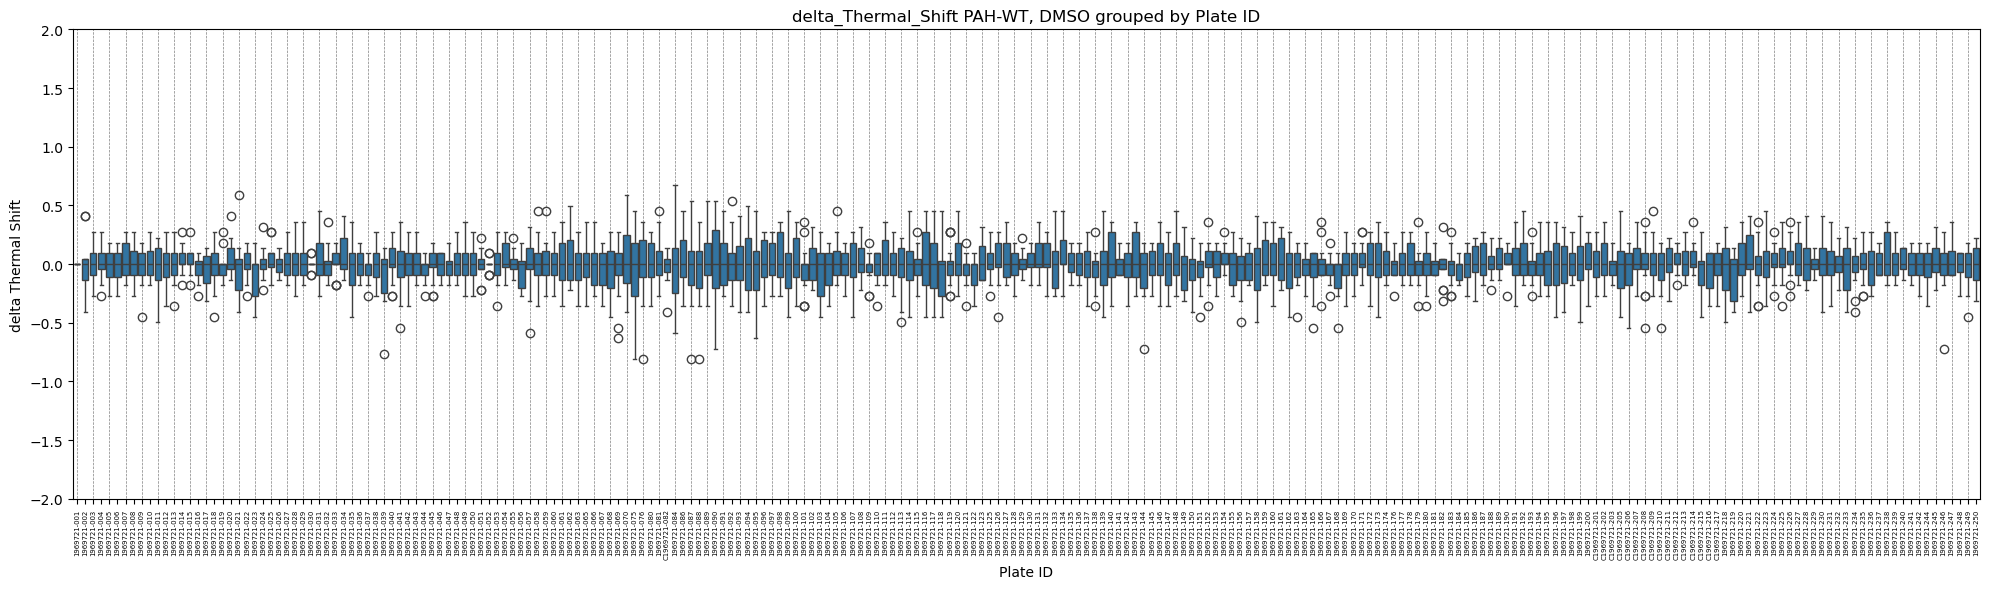

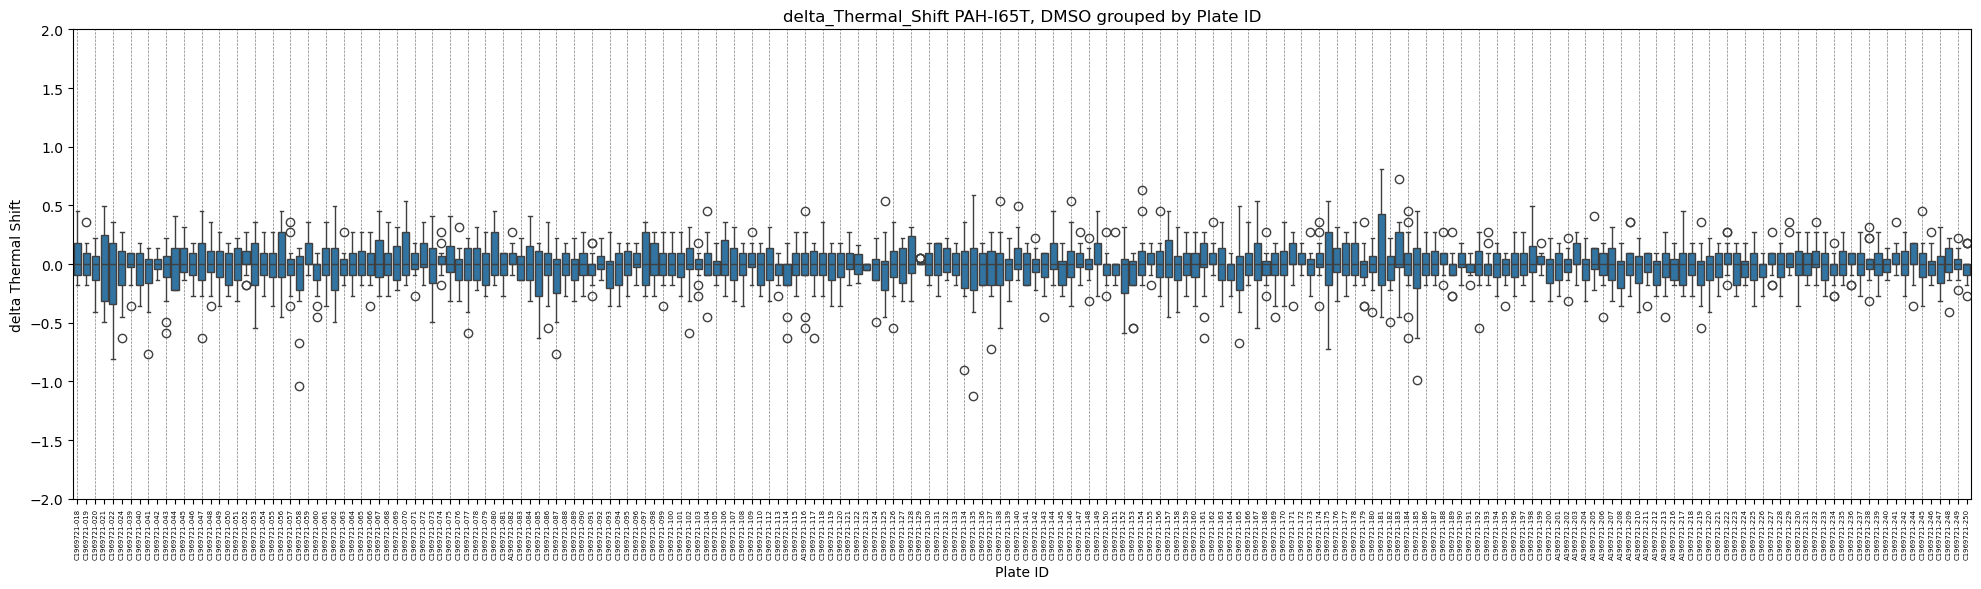

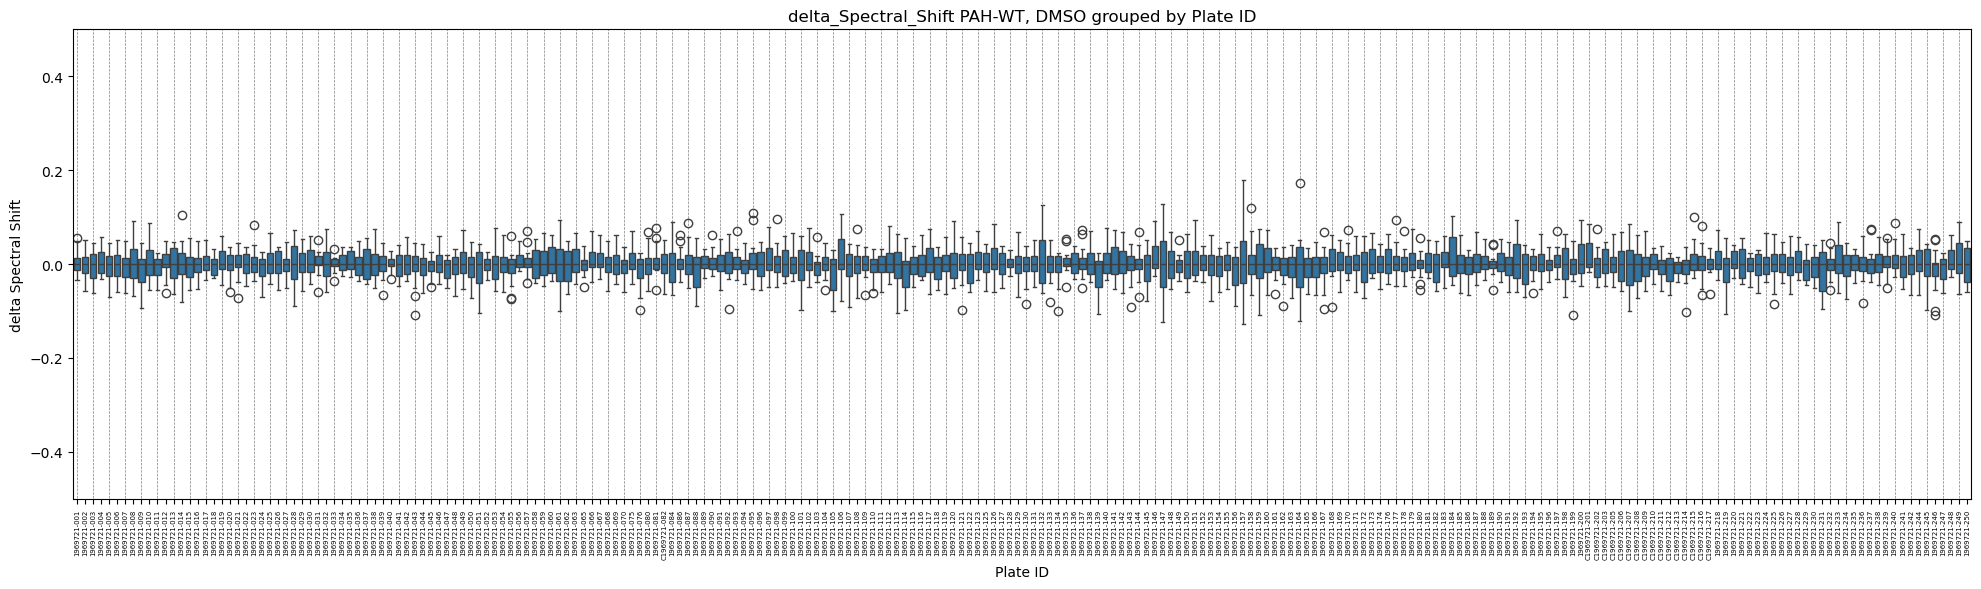

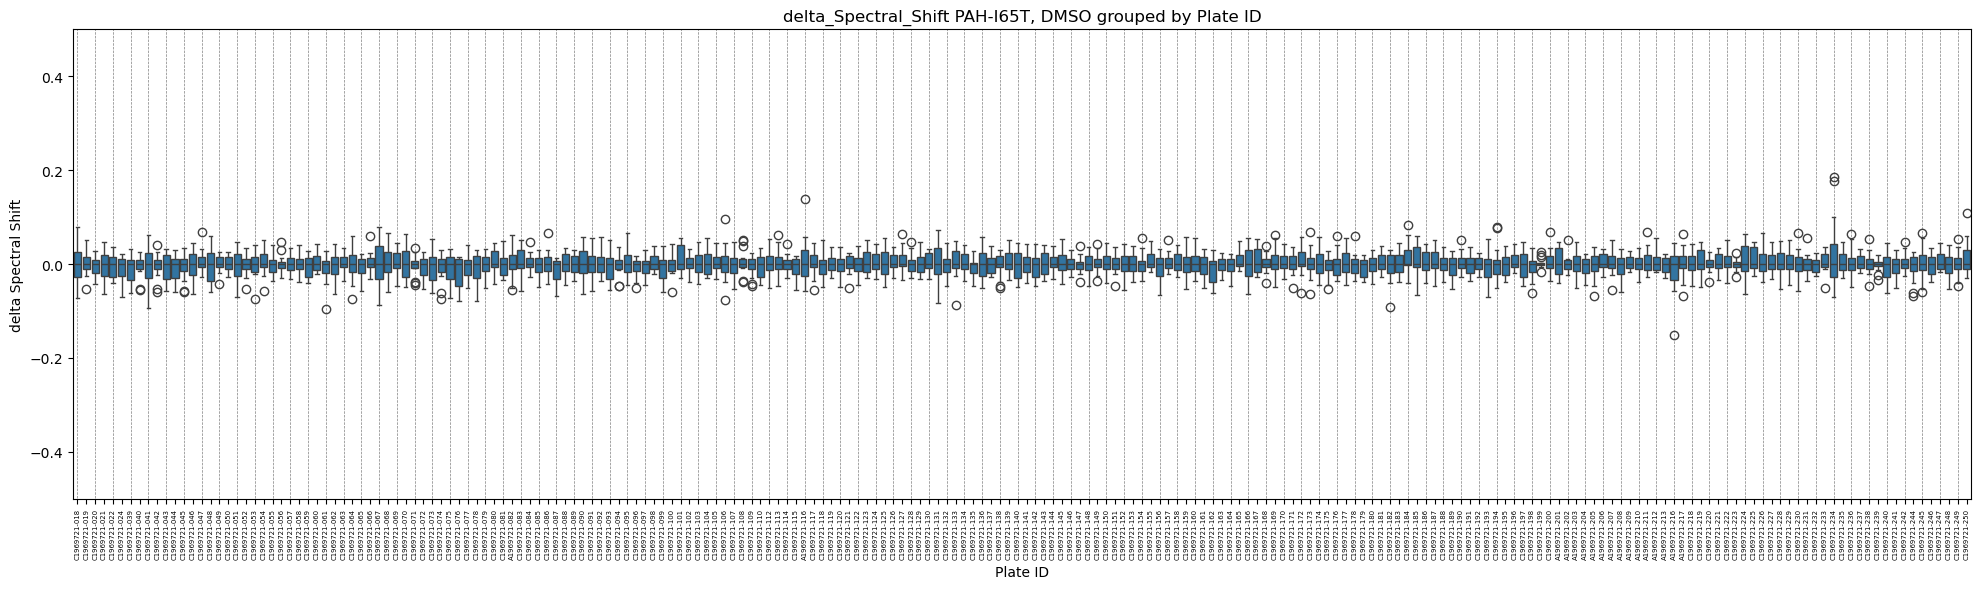

In [41]:
# Plot Delta values DMSO

boxplot_per_plate(df_ctrl, 
                  assay = 'delta_Thermal_Shift', 
                  protein = 'GCDH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-2,2]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'delta_Thermal_Shift', 
                  protein = 'GCDH-R227P', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-2,2]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'delta_Spectral_Shift', 
                  protein = 'GCDH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-.5,.5]
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'delta_Spectral_Shift', 
                  protein = 'GCDH-R227P', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-.5,.5]
                 )

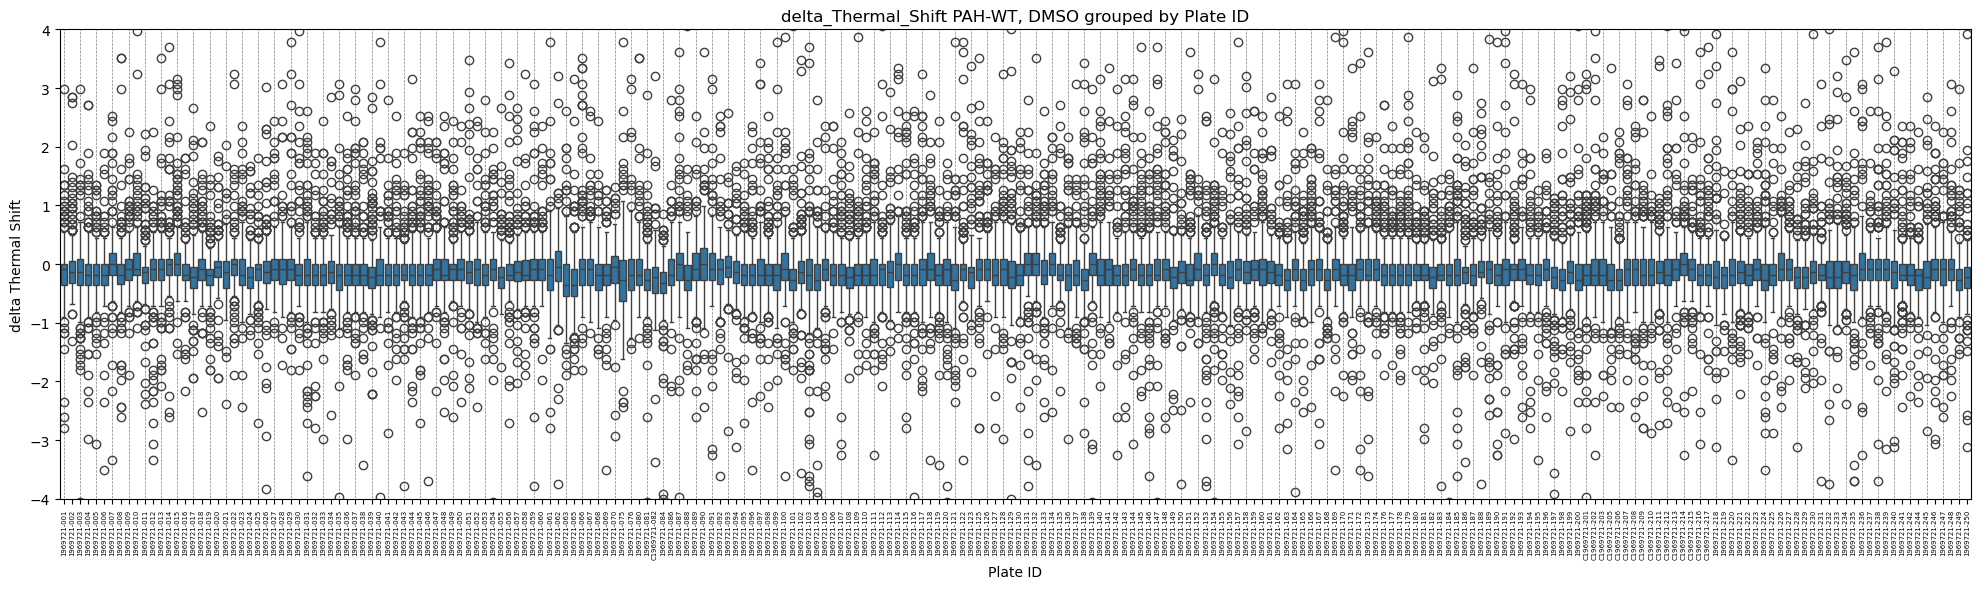

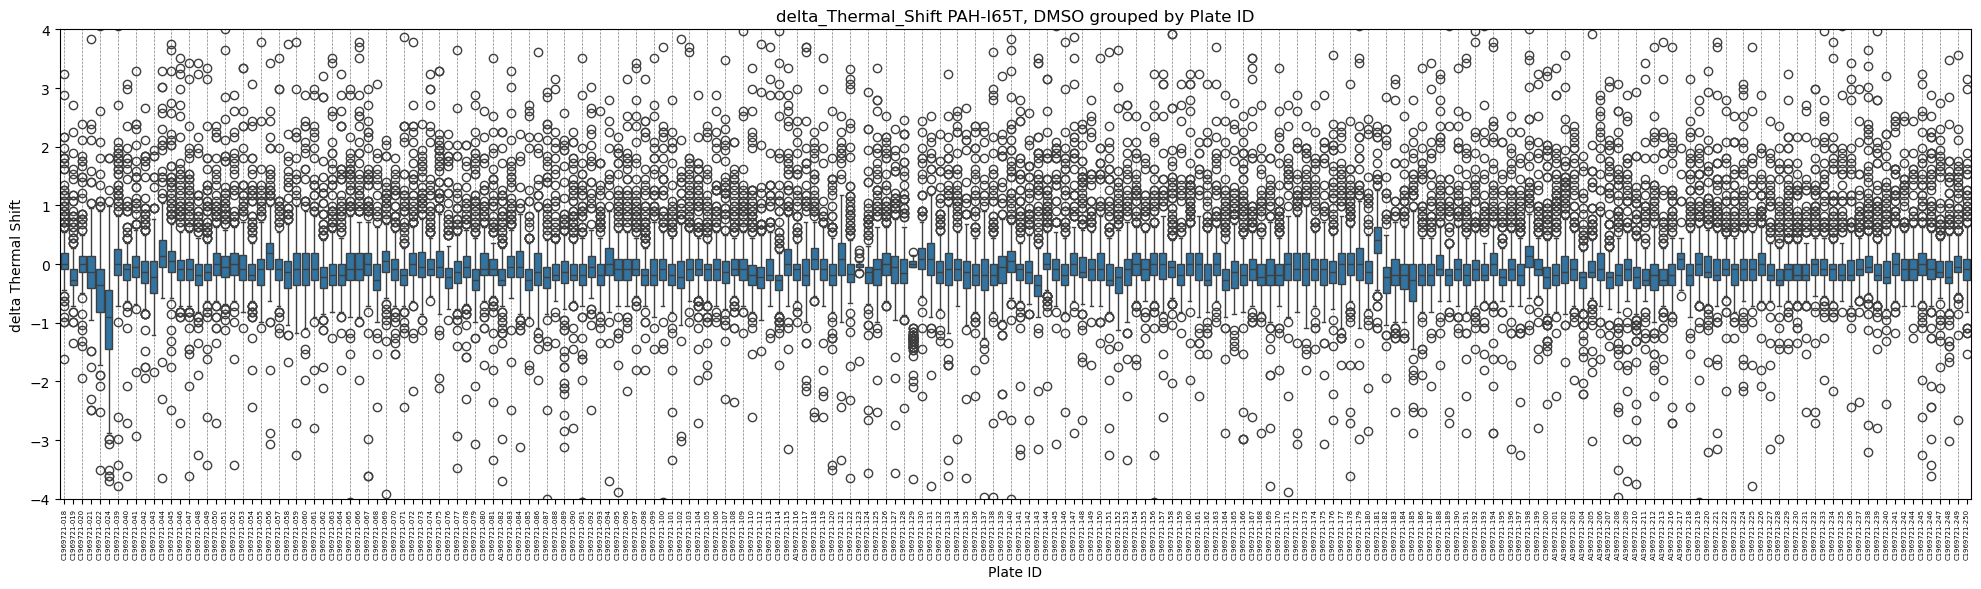

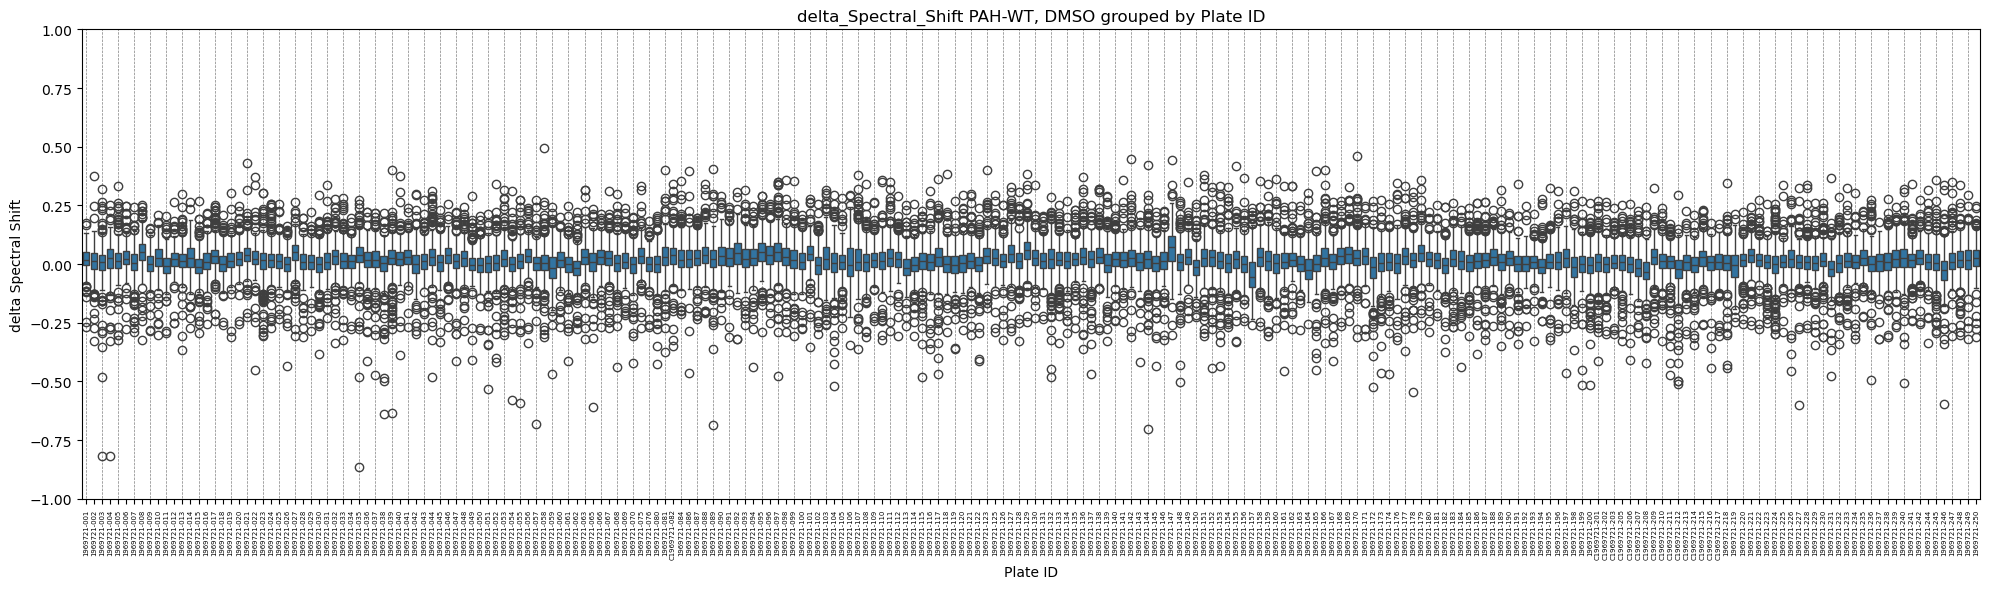

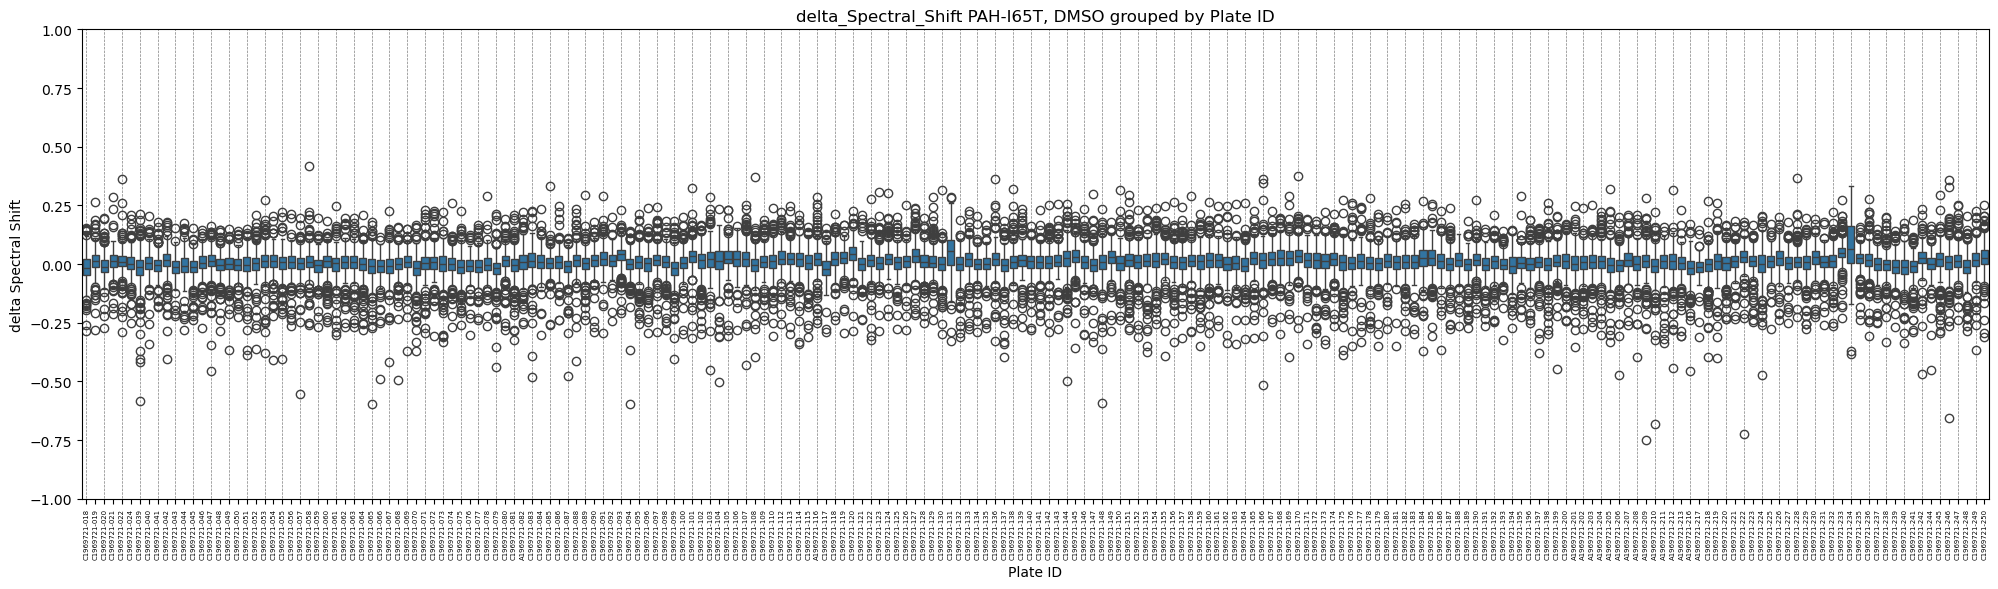

In [44]:
# Plot Delta values olther

boxplot_per_plate(df_other, 
                  assay = 'delta_Thermal_Shift', 
                  protein = 'GCDH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-4, 4]
                 )

boxplot_per_plate(df_other, 
                  assay = 'delta_Thermal_Shift', 
                  protein = 'GCDH-R227P', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-4, 4]
                 )

boxplot_per_plate(df_other, 
                  assay = 'delta_Spectral_Shift', 
                  protein = 'GCDH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-1, 1]
                 )

boxplot_per_plate(df_other, 
                  assay = 'delta_Spectral_Shift', 
                  protein = 'GCDH-R227P', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None,
                  ylim=[-1, 1]
                 )

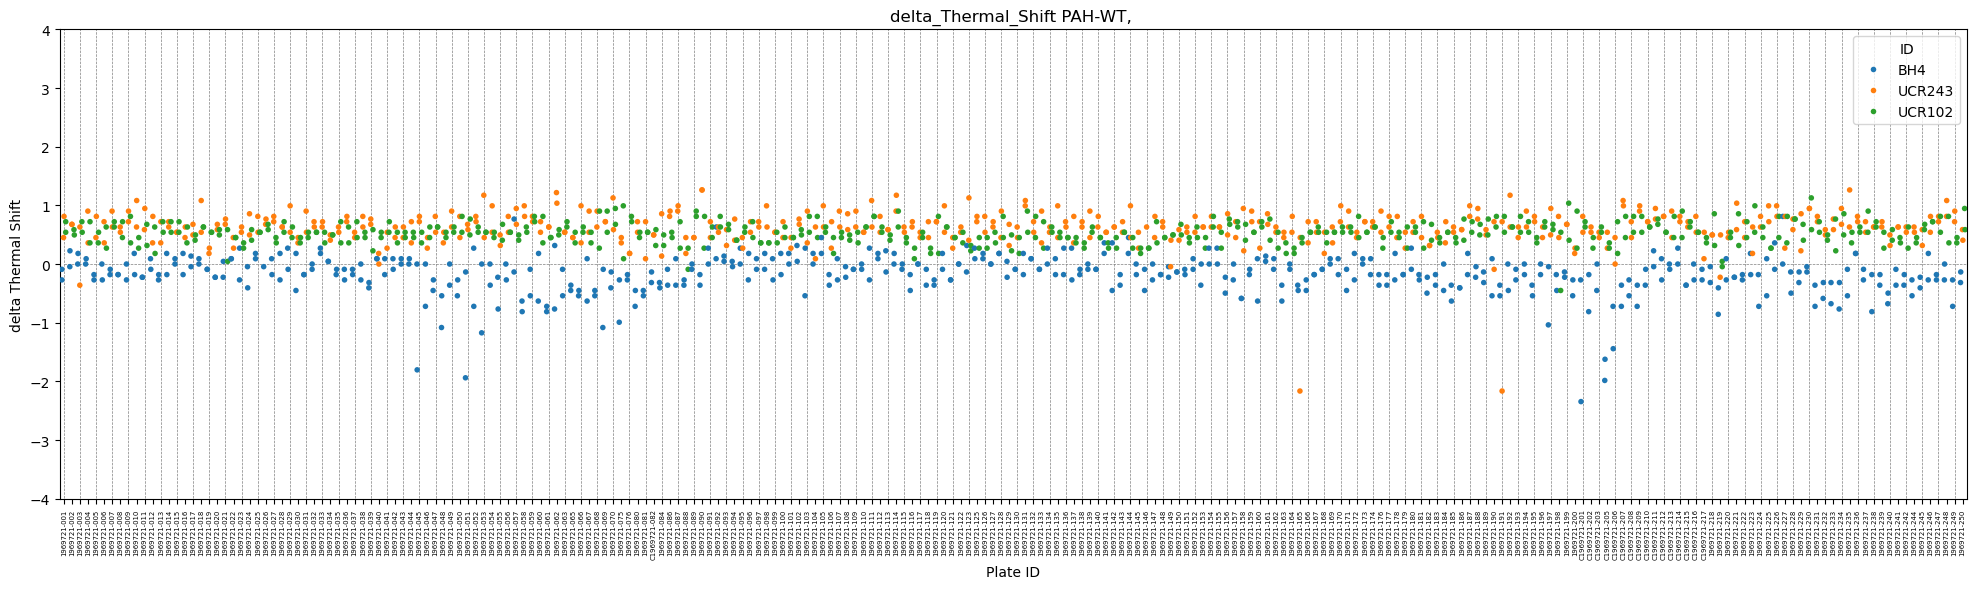

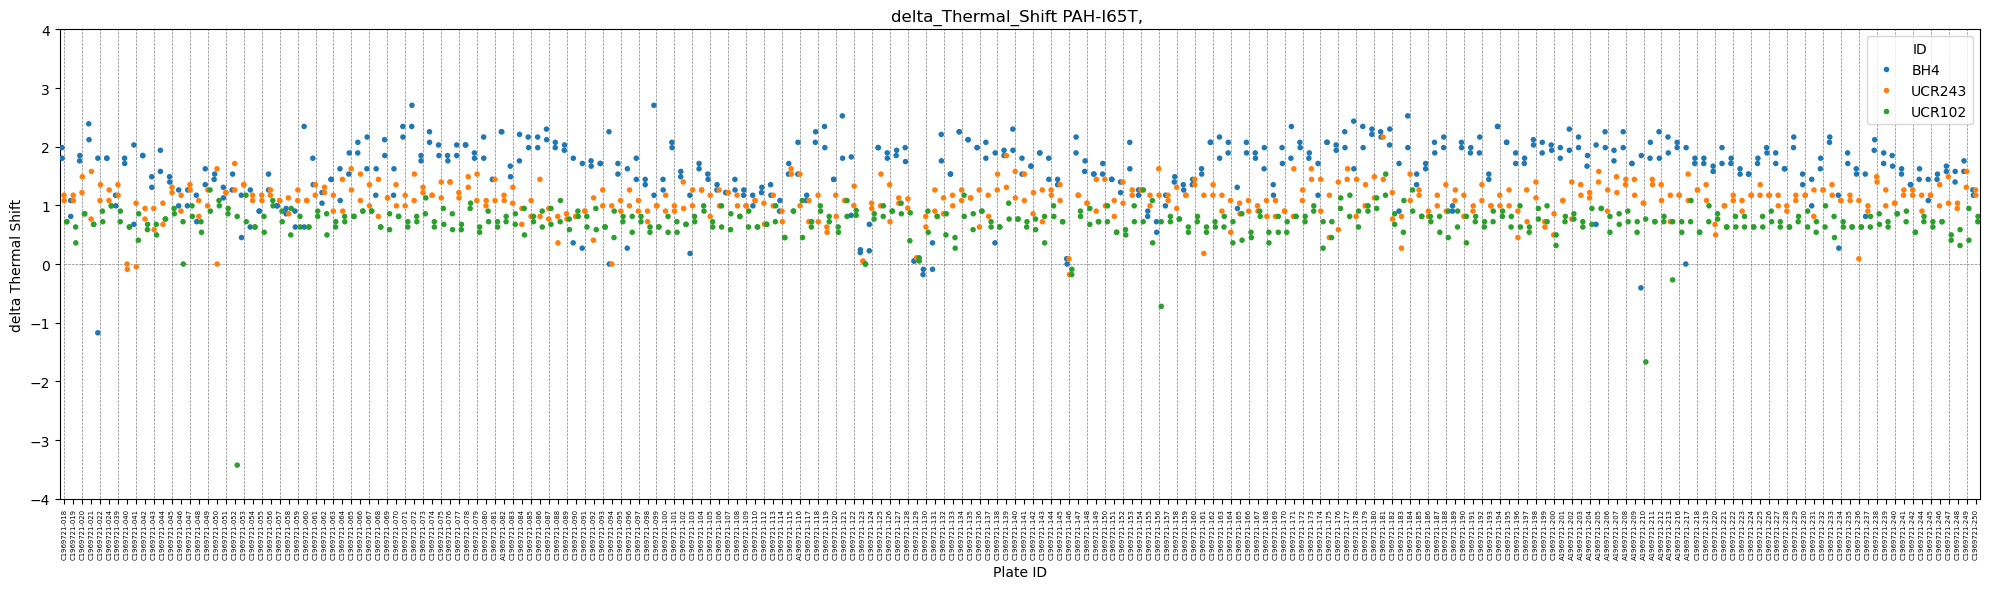

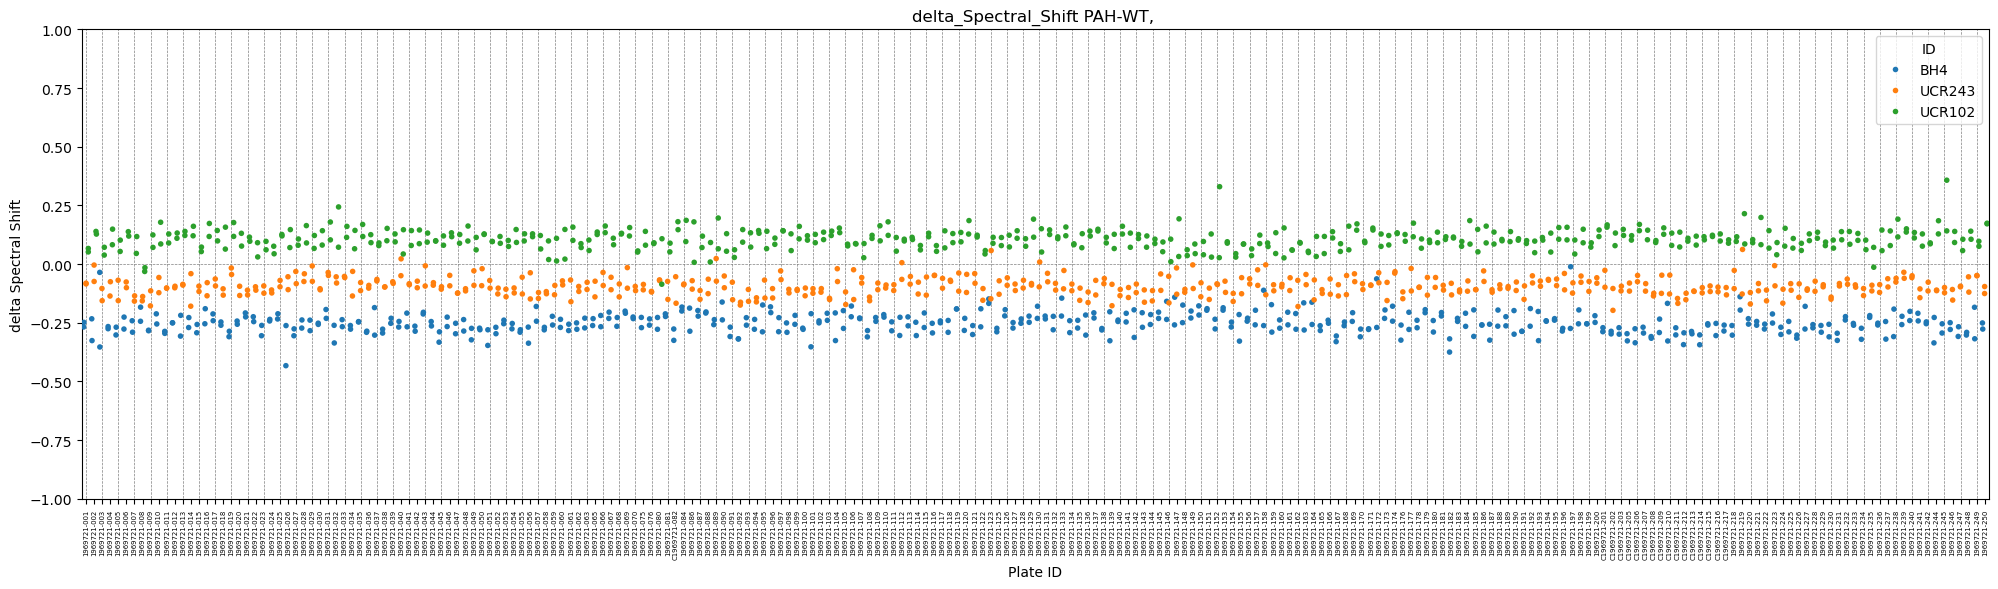

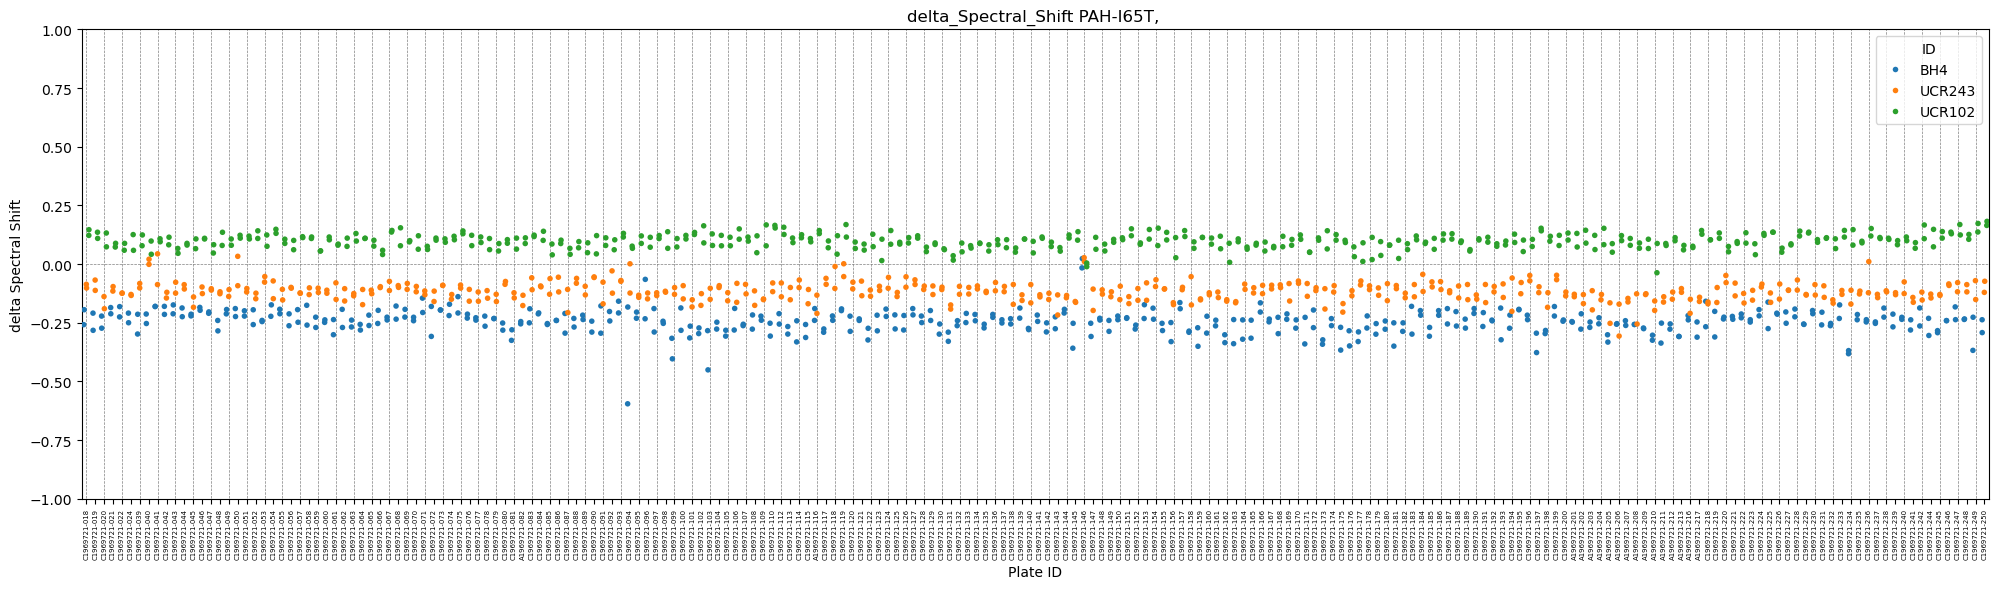

In [47]:
# Plot positive controls

dotplot_per_plate(df_other, 
                  assay = 'delta_Thermal_Shift', 
                  protein = 'GCDH-WT', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-4, 4]
                 )

dotplot_per_plate(df_other, 
                  assay = 'delta_Thermal_Shift', 
                  protein = 'GCDH-R227P', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-4, 4]
                 )

dotplot_per_plate(df_other, 
                  assay = 'delta_Spectral_Shift', 
                  protein = 'GCDH-WT', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-1, 1]
                 )

dotplot_per_plate(df_other, 
                  assay = 'delta_Spectral_Shift', 
                  protein = 'GCDH-R227P', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-1, 1]
                 )

In [48]:
# Complete the QC table by adding the distribuation of positive controls
df_qc_outlier_removed = df_qc.loc[df_qc['out_of_distribution'] == 'no']

df_qc_new = {}
th_set_2 = {}
for protein in ['GCDH-WT', 'GCDH-R227P']:
    df_qc_prot = df_qc_outlier_removed.loc[df_qc_outlier_removed['Protein'] == protein].copy()
    for pos_ctrl in ['BH4', 'UCR243', 'UCR102']:
        for assay in ['delta_Thermal_Shift', 'delta_Spectral_Shift']:
            df_qc_, [thr_min, thr_max] = pos_ctrl_qc(df_other, protein, pos_ctrl, assay)
            df_qc_prot = pd.merge(df_qc_prot, df_qc_, left_index=True, right_index=True, how='outer')
            th_set_2[f'{protein}_{pos_ctrl}_{assay}'] = [thr_min, thr_max]
            
    df_qc_new[protein] = df_qc_prot
df_qc_new = pd.concat(list(df_qc_new.values()))

df_qc_new.head()

,Protein,TSA_median,TSA_iqr,SpSh_median,SpSh_iqr,fl25_median,fl25_iqr,out_of_distribution,abnormal_BH4_delta_Thermal_Shift,abnormal_BH4_delta_Spectral_Shift,abnormal_UCR243_delta_Thermal_Shift,abnormal_UCR243_delta_Spectral_Shift,abnormal_UCR102_delta_Thermal_Shift,abnormal_UCR102_delta_Spectral_Shift
1969721-001,PAH-WT,49.4840,0.00000,2.903465,0.031402,-32414.554826,2734.591900,no,0.0,0.0,0.0,0.0,0.0,0.0
1969721-002,PAH-WT,49.3487,0.18040,3.001054,0.034008,-27865.316910,1905.986941,no,0.0,0.0,0.0,0.0,0.0,0.0
1969721-003,PAH-WT,49.2134,0.18040,2.976828,0.049121,-29299.307264,2267.008084,no,0.0,1.0,1.0,0.0,0.0,0.0
1969721-004,PAH-WT,49.4840,0.13520,2.972701,0.043583,-30133.408495,2838.254957,no,0.0,0.0,0.0,0.0,0.0,0.0
1969721-005,PAH-WT,49.3036,0.20295,2.897231,0.044305,-31840.723069,1322.385006,no,0.0,0.0,0.0,0.0,0.0,0.0


In [49]:
df_qc_new.loc['C1969721-205']

Protein                                       PAH-WT
TSA_median                                   48.8527
TSA_iqr                                     0.315675
SpSh_median                                 2.981141
SpSh_iqr                                    0.032759
fl25_median                            -23093.025058
fl25_iqr                                 2081.497476
out_of_distribution                               no
abnormal_BH4_delta_Thermal_Shift                 2.0
abnormal_BH4_delta_Spectral_Shift                0.0
abnormal_UCR243_delta_Thermal_Shift              0.0
abnormal_UCR243_delta_Spectral_Shift             0.0
abnormal_UCR102_delta_Thermal_Shift              0.0
abnormal_UCR102_delta_Spectral_Shift             0.0
Name: C1969721-205, dtype: object

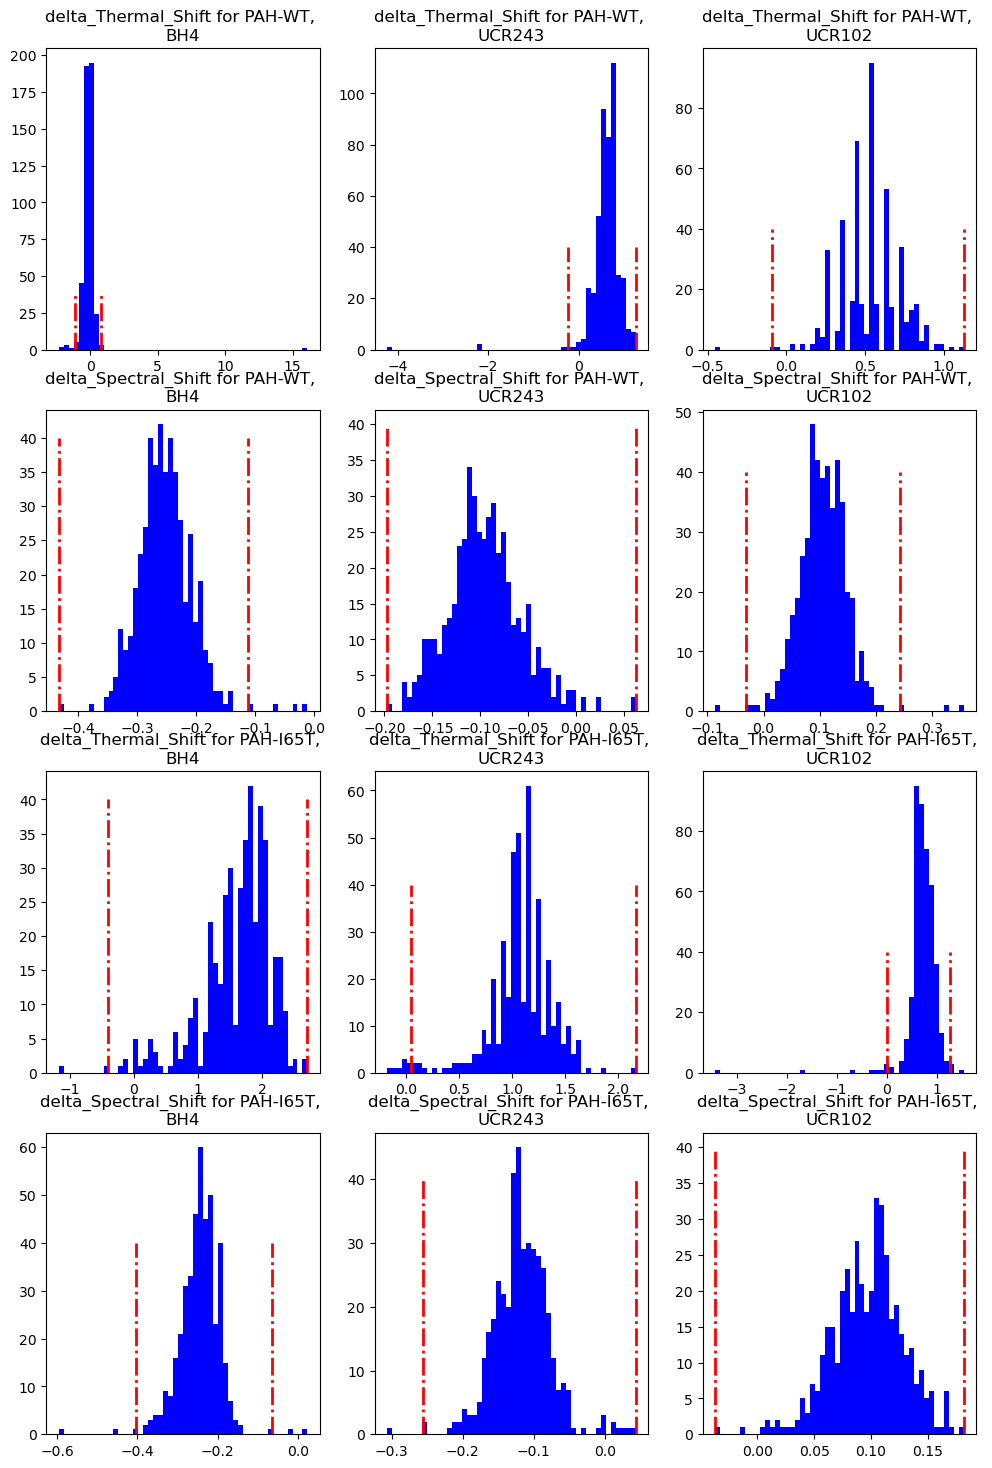

In [56]:
# ditribution of pos control with thershold
fig, ax = plt.subplots(4, 3, figsize=(12, 18))
ax = ax.flatten()

i = 0
for protein in ['GCDH-WT', 'GCDH-R227P']:
    df_qc_prot = df_other.loc[df_other['Protein'] == protein].copy()
    for assay in ['delta_Thermal_Shift', 'delta_Spectral_Shift']:
        for pos_ctrl in ['BH4', 'UCR243', 'UCR102']:
            df_qc_prot_ctrl = df_qc_prot.loc[df_qc_prot['ID'] == pos_ctrl].copy()
            
            ax[i].hist(df_qc_prot_ctrl[assay], 50, color='blue');
            ax[i].vlines(th_set_2[f'{protein}_{pos_ctrl}_{assay}'], ymin=0, ymax=40, colors='red', linestyles='-.', linewidth=2)
            ax[i].set_title(f'{assay} for {protein}, \n{pos_ctrl}');
            i += 1

In [51]:
sum_abnormal_all_pos_ctrls = np.array(df_qc_new.iloc[:,8:]).sum(1)
sum_abnormal_UCRs = np.array(df_qc_new.iloc[:,10:]).sum(1)

df_qc_new['sum_abnormal_all_pos_ctrls'] = sum_abnormal_all_pos_ctrls
df_qc_new['sum_abnormal_UCRs'] = sum_abnormal_UCRs

In [52]:
df_qc_new['sum_abnormal_all_pos_ctrls'].value_counts().sort_index()

sum_abnormal_all_pos_ctrls
0.0    421
1.0     24
2.0      4
5.0      1
Name: count, dtype: int64

In [53]:
df_qc_new['sum_abnormal_UCRs'].value_counts().sort_index()

sum_abnormal_UCRs
0.0    431
1.0     17
2.0      1
3.0      1
Name: count, dtype: int64

In [54]:
# Are all nan values are those that are out of distriubution? yes

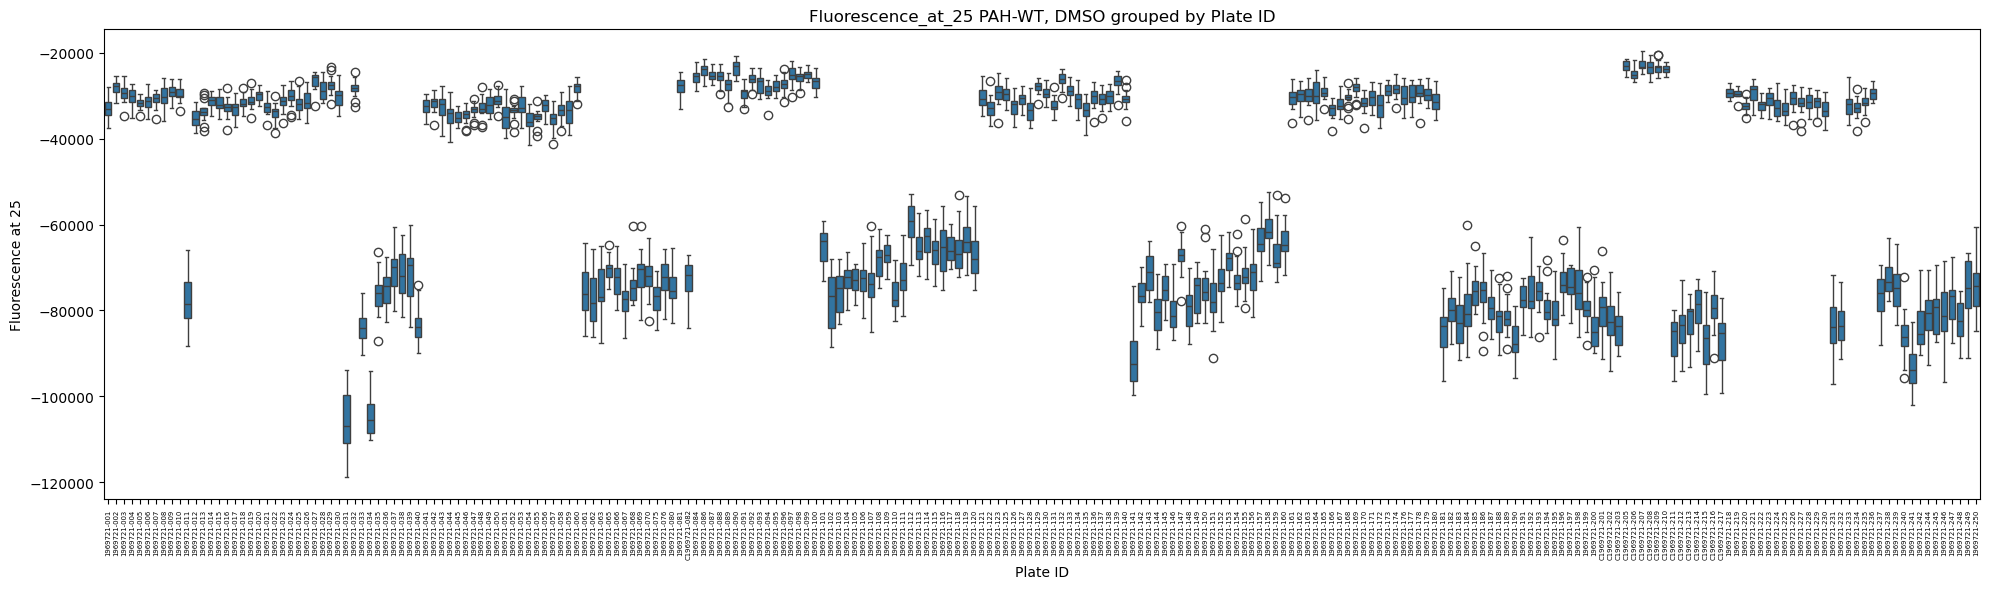

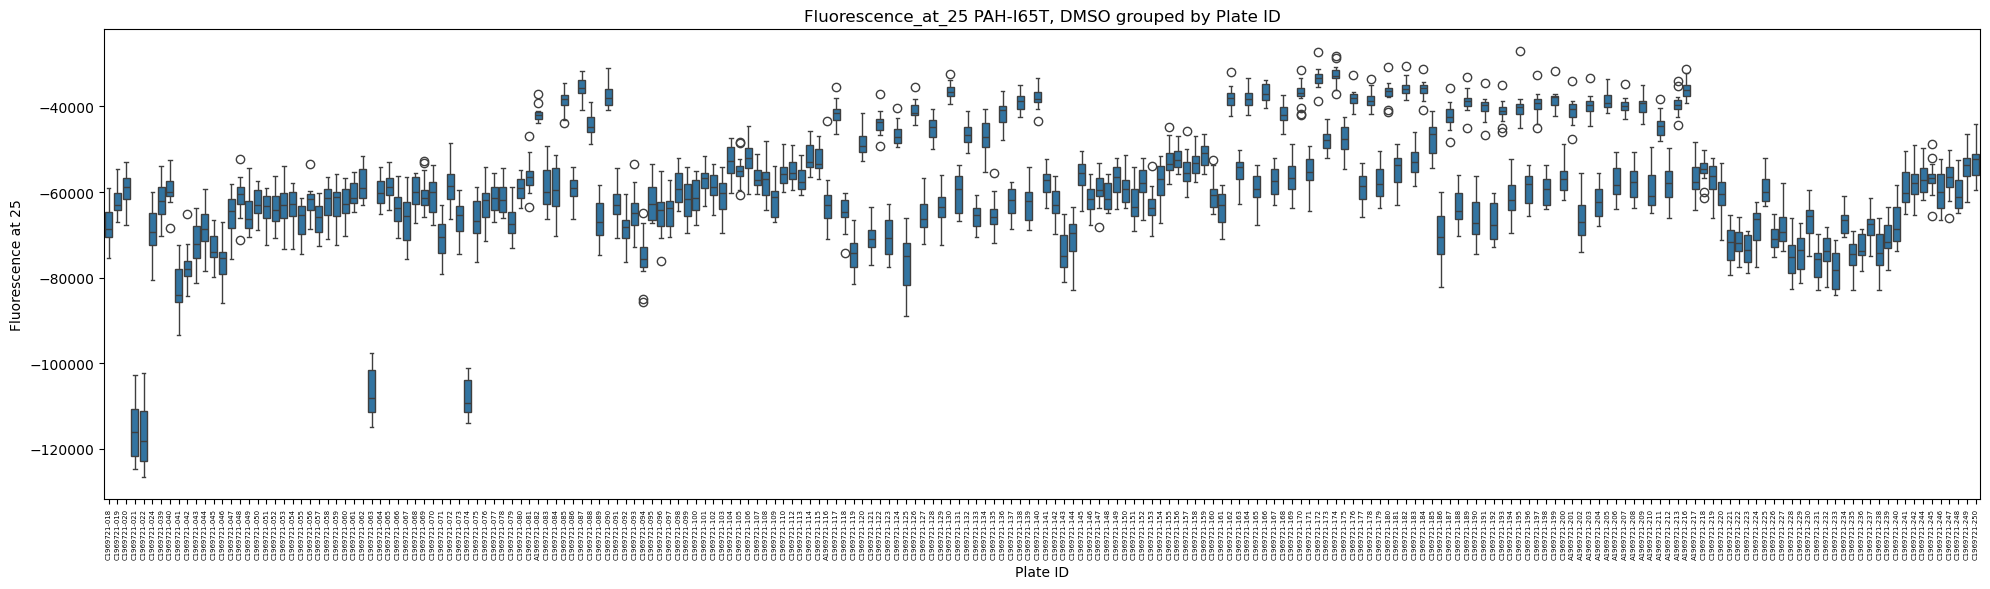

In [55]:
boxplot_per_plate(df_ctrl, 
                  assay = 'Fluorescence_at_25', 
                  protein = 'GCDH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Fluorescence_at_25', 
                  protein = 'GCDH-R227P', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

In [ ]:
# Save
print(save_tag)
df_other.to_csv(f"data/PO_processed_{save_tag}.csv")
df_ctrl.to_csv(f"data/PO_processed_dmso_{save_tag}.csv")
df_qc_new.to_csv(f"data/qc_table_alpha_01_bonf_{save_tag}.csv")